# 03 — Fusion Audio–Video dan Sintesis Kesiapan Riset

> **Dataset:** RAVDESS paired AV · **Target:** emotion, bukan fatigue  
> **Unit:** recording pada aktor holdout · **Visual:** appearance HOG 2 FPS, bukan blink/PERCLOS  
> **Mode default:** DEMO — cache fitur FULL terverifikasi + inference checkpoint; ekstraksi contoh hanya sesi privat/FULL

[README proyek](../../README.md) · [Sumber RAVDESS](https://zenodo.org/records/1188976) · [Batas metodologi](../../reports/limitations.md) · [Reproduksi](README.md)

## Ringkasan untuk Pembaca

Audio dan gambar dapat membawa informasi yang berbeda dari satu rekaman. Kita mengekstrak keduanya, melatih baseline unimodal dan fusion, lalu menilai rekaman aktor yang tidak masuk training. Tugas pengujian ini adalah **emosi aktor**; keberhasilan prosesnya membantu menyiapkan penelitian fatigue, tetapi bukan skor deteksi fatigue ATC.

### Rute presentasi 10–15 menit

1. [Pertanyaan dan peta bukti](#1-pertanyaan-dan-peta-bukti) — 2 menit.
2. [Pasangan AV dan fitur langsung](#2-pasangan-asli-dan-transformasi-fitur) — 2 menit.
3. [Split dan keterbatasan](#3-eda-dan-split-aktor-yang-dibekukan) — 2 menit.
4. [Training serta hasil](#4-training-dan-evaluasi-empat-model) — 3 menit.
5. [Ablation serta inference](#5-modalitas-hilang-dan-inference-heldout) — 2 menit.
6. [Sintesis untuk Prof](#6-sintesis-kesiapan-penelitian) — 2 menit.

Detail kode tetap tersedia dalam notebook yang sama. Tidak diperlukan variabel dari notebook sebelumnya.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')
from atc_fatigue.research.data import private_media_enabled
from atc_fatigue.research.representations import inspect_model_input, audio_feature_group
PRIVATE_MEDIA = private_media_enabled()
USE_SOURCE_MEDIA = RUN_MODE == 'FULL' or PRIVATE_MEDIA
print('Media sumber:', 'FRESH lokal' if USE_SOURCE_MEDIA else 'tidak dibaca; DEMO memakai cache terverifikasi')

if os.environ.get('ATC_NOTEBOOK_DENY_RAW_MEDIA') == '1':
    from atc_fatigue.research.data import deny_raw_media_reads
    deny_raw_media_reads()
    print('ACCEPTANCE: pembacaan data/raw diblokir pada proses kernel ini.')

source_state = "REAL / FRESH" if RUN_MODE == "FULL" else "REAL / CACHED features; FRESH checkpoint inference"


Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek
Media sumber: tidak dibaca; DEMO memakai cache terverifikasi
ACCEPTANCE: pembacaan data/raw diblokir pada proses kernel ini.


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="1-pertanyaan-dan-peta-bukti"></a>

## 1. Pertanyaan dan peta bukti

**Pertanyaan:** apakah audio dan video dari recording asli yang sama bisa diproses, dilatih, dan dievaluasi secara adil terhadap model satu modalitas?

**Fusion** berarti menggabungkan informasi beberapa modalitas. Pada baseline ini, vektor audio dan visual disambung (*feature concatenation*), lalu classifier mempelajari label emotion. **Macro F1** adalah rerata F1 tiap kelas; F1 menyeimbangkan ketepatan prediksi dan kemampuan menemukan anggota kelas. **Balanced accuracy** adalah rerata recall tiap kelas.

Fatigue = kelelahan akibat tuntutan berkelanjutan; sleepiness = kecenderungan tertidur; workload = tuntutan mental; stress = respons tekanan. **Emotion** dan **eye state** adalah label berbeda lagi. Kita tidak mengganti satu target dengan target lain.

| Sumber bukti | Pertanyaan yang benar-benar diuji | Yang belum dibuktikan |
| :--- | :--- | :--- |
| ATCOSIM | Bisakah suara ATC menjadi fitur? | Akurasi fatigue dari suara |
| MRL | Bisakah gambar mata dikenali open/closed? | Fatigue operator |
| DROZY | Bisakah fitur mata memperkirakan KSS sleepiness? | Real-time fatigue ATC |
| RAVDESS | Bisakah paired AV dipakai untuk emotion fusion? | Fusion fisiologis fatigue ATC |

RAVDESS: Livingstone & Russo (2018), DOI `10.1371/journal.pone.0196391`, CC BY-NC-SA 4.0. Notebook mempertahankan atribusi dan tidak membagikan media sumber. Tabel/grafik agregat dan ilustrasi tanpa wajah cukup untuk presentasi proses.

In [2]:
ravdess_manifest = local_manifest(config['fusion']['ravdess_manifest'],target='emotion',verify_media=USE_SOURCE_MEDIA)
ravdess_rights = {'source':'https://zenodo.org/records/1188976',
                  'variant':'AV speech; actors 01–08; normal intensity; statement 01; two repetitions',
                  'rights':'CC BY-NC-SA 4.0; Livingstone & Russo (2018)', 'public_preview':'aggregate charts, no raw faces/voice'}
ravdess_limits = ['emotion not fatigue; 8 actors / tiny heldout subset',
                  'original male-only train, female-only validation/test; demographic domain shift',
                  'face HOG 2fps is appearance, not blink/EAR/PERCLOS',
                  'inference ablation is not missing-modality robustness training',
                  'previously observed fixed holdout; rerun is not new independent evidence']
if RUN_MODE=='FULL':
    fusion_run = Run.create('ravdess_emotion','03_multimodal_fusion.ipynb',config,ravdess_manifest,
                            'audio-egemapsv02-mfcc13-v1; sampled-face-hog-2fps-v1',ravdess_rights,ravdess_limits)
else:
    fusion_run,fusion_metrics = cached_run('ravdess_emotion',config)
fusion_book = FigureBook(fusion_run,RUN_MODE,config)
run_card(fusion_run,RUN_MODE,'FULL: dihitung pada evaluasi' if RUN_MODE=='FULL' else
         f"Emotion Macro F1 {fusion_metrics['models']['audio_visual']['test']['macro_f1']:.4f} / 32 klip test")

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261023T104859625424Z_seed42_cce30b` |
| Status eksperimen sumber | completed |
| Dataset / target | ravdess / emotion |
| Sampel / subjek | 128 / 8 |
| Unit evaluasi | AV_recording; held-out actor |
| Hasil utama | Emotion Macro F1 0.4549 / 32 klip test |

<a id="2-pasangan-asli-dan-transformasi-fitur"></a>

## 2. Pasangan asli dan transformasi fitur

File RAVDESS modality `01` berisi **dua stream dalam container AV yang sama**. Identitas file dan checksum menjadi bukti pasangan; kita tidak menyambungkan dataset atau waktu yang tidak berhubungan. Timestamps stream diperiksa melalui `ffprobe`.

Audio menjadi **88 eGeMAPS** (paket ringkasan fitur suara) + **26 MFCC** (rerata/simpangan baku 13 koefisien spektral). Visual menjadi **HOG** (ringkasan arah tepi wajah) yang disampel 2 frame/detik dan diringkas rerata/simpangan baku. **Sampling 2 FPS tidak memadai untuk mengukur kedipan**; cabang fisiologis EAR/PERCLOS untuk paired ATC belum diuji di sini.

In [3]:
from atc_fatigue.research.data import paired_sample, pseudonym
from atc_fatigue.models.baselines import classification_metrics
predeclared_split = frozen_split(ravdess_manifest,config['frozen_splits']['ravdess_emotion'])
example_id = predeclared_split.loc[predeclared_split.split.eq('test'),'sample_id'].iloc[0]
heldout_source = ravdess_manifest[ravdess_manifest.sample_id.eq(example_id)].iloc[0]
if USE_SOURCE_MEDIA:
    live_output = fusion_run.file('features/live_example.wav') if RUN_MODE=='FULL' else fusion_book.directory.parent / 'live_example.wav'
    live_paired_features = paired_sample(heldout_source,config,live_output)
else:
    cached_pairs = pd.read_parquet(fusion_run.path/'features/features.parquet')
    live_paired_features = cached_pairs.loc[cached_pairs.sample_id.eq(example_id)].iloc[0].to_dict()
print('FRESH: decode satu AV sumber' if USE_SOURCE_MEDIA else 'CACHED: fitur dari satu AV sumber; FRESH: inference checkpoint di bawah')
display(pd.DataFrame([{'Contoh holdout':pseudonym(example_id),'Target':'emotion',
                       'Label asli':EMOTIONS[int(heldout_source.target_value)],
                       'Pasangan':'audio + video dari satu file AV',
                       'Durasi video (s)':live_paired_features['video_duration_ms']/1000,
                       'Offset start audio − video (s)':live_paired_features['stream_offset_seconds'],
                       'Audio tersedia':live_paired_features['audio_available'],
                       'Video tersedia':live_paired_features['video_available']}]))
assert live_paired_features['paired_recording_verified']
assert heldout_source.sample_id in set(predeclared_split[predeclared_split.split.eq('test')].sample_id)

CACHED: fitur dari satu AV sumber; FRESH: inference checkpoint di bawah


,Contoh holdout,Target,Label asli,Pasangan,Durasi video (s),Offset start audio − video (s),Audio tersedia,Video tersedia
0,contoh-61881241,emotion,Netral,audio + video dari satu file AV,3.636967,0.0,True,True


### Lihat recording paired AV yang benar-benar dipakai

[Video + audio asli dari test recording pertama](../../assets/demo_media/ravdess_paired_example.mp4) dan frame sekitar0,5detik berikut berasal dari container yang sama dengan contoh di atas.

![RAVDESS REAL / frame dari AV test recording yang sama](../../assets/demo_media/ravdess_frame.jpg)

**Yang terlihat:** frame memperlihatkan input visual asli; bukan wajah sintetis atau pasangan lintas dataset. **Artinya:** dua modalitas dapat ditelusuri ke satu source checksum. **Perlu diingat:** targetnya emotion, bukan fatigue; satu frame tidak memberikan blink duration/PERCLOS.

Sumber: Steven R. Livingstone dan Frank A. Russo(2018), [RAVDESS](https://doi.org/10.5281/zenodo.1188976), [CC BY-NC-SA4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). MP4 tetap asli, JPEG merupakan ekstraksi frame tanpa cropping dan dibagikan dengan lisensi sama untuk penggunaan nonkomersial. [Kredit, perubahan dan checksum](../../assets/demo_media/README.md). Jika preview tidak muncul, pilih **Download raw file** pada tautan MP4.

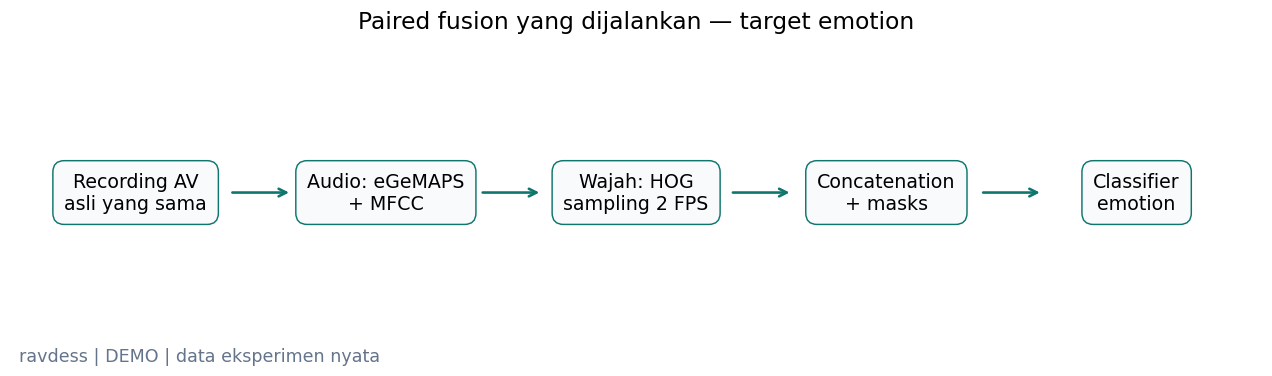

**Yang terlihat:** Kedua modalitas berasal dari checksum file sumber yang sama.

**Artinya:** Baseline dapat menguji manfaat fitur gabungan tanpa membuat pasangan palsu.

**Perlu diingat:** Diagram ini memakai HOG appearance; cabang EAR/PERCLOS fatigue ATC adalah pekerjaan berikutnya.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [4]:
fig = flow(['Recording AV\nasli yang sama', 'Audio: eGeMAPS\n+ MFCC', 'Wajah: HOG\nsampling 2 FPS', 'Concatenation\n+ masks', 'Classifier\nemotion'],
           COLORS['fusion'],'Paired fusion yang dijalankan — target emotion')
fusion_book.show(fig,'alur_paired_fusion','Kedua modalitas berasal dari checksum file sumber yang sama.',
                 'Baseline dapat menguji manfaat fitur gabungan tanpa membuat pasangan palsu.',
                 'Diagram ini memakai HOG appearance; cabang EAR/PERCLOS fatigue ATC adalah pekerjaan berikutnya.')

### Ekstraksi seluruh subset pada FULL

Satu contoh holdout diproses dari media pada FULL/DEMO privat; DEMO publik membaca fitur cache terverifikasi. FULL meneruskan ekstraksi untuk seluruh recording lokal, menyimpan audio turunan hanya di run baru, dan memverifikasi source checksum/stream. DEMO menggunakan tabel FULL terverifikasi untuk bagian mahal, memverifikasi schema dan provenance cache; sesi privat juga mencocokkan ekstraksi contoh langsung dengan cache.

**Availability mask** menandai fitur tersedia atau hilang. Kegagalan tidak diubah menjadi pitch nol atau HOG nol yang dianggap pengukuran asli; preprocessing menangani nilai hilang berdasarkan training saja.

In [5]:
if RUN_MODE=='FULL':
    paired_rows = []
    extraction_started = time.perf_counter()
    for index,row in ravdess_manifest.iterrows():
        if row.sample_id==example_id:
            paired_rows.append(live_paired_features)
        else:
            decoded_audio = fusion_run.file(f'features/decoded_audio/{row.sample_id}.wav')
            paired_rows.append(paired_sample(row,config,decoded_audio))
        if (index+1)%32==0:
            print(f'Ekstraksi AV {index+1}/{len(ravdess_manifest)} selesai')
    paired_features = pd.DataFrame(paired_rows)
    fusion_data = frozen_split(paired_features,config['frozen_splits']['ravdess_emotion'])
    fusion_run.log('extract_all_paired',{'rows':len(fusion_data),'seconds':time.perf_counter()-extraction_started})
else:
    fusion_data = pd.read_parquet(fusion_run.path / 'features/features.parquet')
    assert set(fusion_data.sample_id)==set(ravdess_manifest.sample_id)
audio_columns = [c for c in fusion_data if c.startswith(('egemaps__','mfcc_'))]
visual_columns = [c for c in fusion_data if c.startswith('visual_hog_')]
fusion_columns = audio_columns+visual_columns+['audio_available','video_available']
assert fusion_data.paired_recording_verified.all() and len(audio_columns)==114
np.testing.assert_allclose(fusion_data.loc[fusion_data.sample_id.eq(example_id),audio_columns+visual_columns].iloc[0].to_numpy(float),
                           np.array([live_paired_features[c] for c in audio_columns+visual_columns]),equal_nan=True,rtol=1e-5,atol=1e-7)
display(fusion_data[['duration_seconds','face_detection_rate','audio_available','video_available']].head())
display(pd.DataFrame([{'Fitur audio':len(audio_columns),'Fitur visual':len(visual_columns),
                       'Masks':2,'Dimensi fusion':len(fusion_columns)}]))

,duration_seconds,face_detection_rate,audio_available,video_available
0,3.306687,1.0,True,True
1,3.349312,1.0,True,True
2,3.541313,1.0,True,True
3,3.605313,1.0,True,True
4,3.477313,1.0,True,True


,Fitur audio,Fitur visual,Masks,Dimensi fusion
0,114,3528,2,3644


<a id="3-eda-dan-split-aktor-yang-dibekukan"></a>

## 3. EDA dan split aktor yang dibekukan

EDA (*exploratory data analysis*) memeriksa apa yang benar-benar ada sebelum menafsirkan model. Delapan emotion classes berasal dari filename resmi. Subset hanya normal intensity dan satu statement, sehingga variasi yang tersedia lebih sempit daripada seluruh RAVDESS.

Split ditahan per aktor: orang yang sama tidak melintasi train/validation/test. Kita memakai keanggotaan run lama, tanpa tuning ulang setelah test diamati. Rerun ini menguji reproduksibilitas dan proses notebook; bukan test independen yang baru.

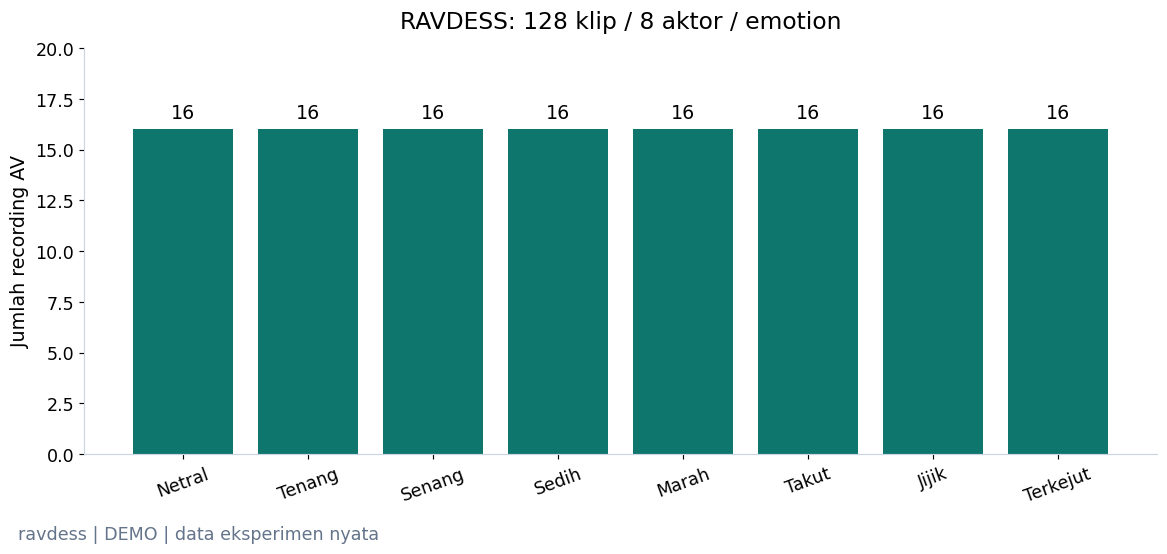

**Yang terlihat:** Setiap kelas memiliki 16–16 klip pada subset ini.

**Artinya:** Keseimbangan label membantu membandingkan model, sementara ukuran aktor tetap kecil.

**Perlu diingat:** Emotion adalah ekspresi aktor; label ini bukan penilaian fatigue operator.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [6]:
class_counts = fusion_data.target_value.value_counts().sort_index()
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar([EMOTIONS[int(x)] for x in class_counts.index],class_counts.values,color=COLORS['fusion'])
ax.bar_label(bars,padding=5)
ax.set(ylabel='Jumlah recording AV',ylim=(0,class_counts.max()*1.25),
       title=f'RAVDESS: {len(fusion_data)} klip / {fusion_data.subject_id.nunique()} aktor / emotion')
ax.tick_params(axis='x',labelrotation=20)
fusion_book.show(fig,'distribusi_emotion',
                 f'Setiap kelas memiliki {class_counts.min()}–{class_counts.max()} klip pada subset ini.',
                 'Keseimbangan label membantu membandingkan model, sementara ukuran aktor tetap kecil.',
                 'Emotion adalah ekspresi aktor; label ini bukan penilaian fatigue operator.')

,Klip,Aktor
split,,
test,32,2
train,64,4
validation,32,2


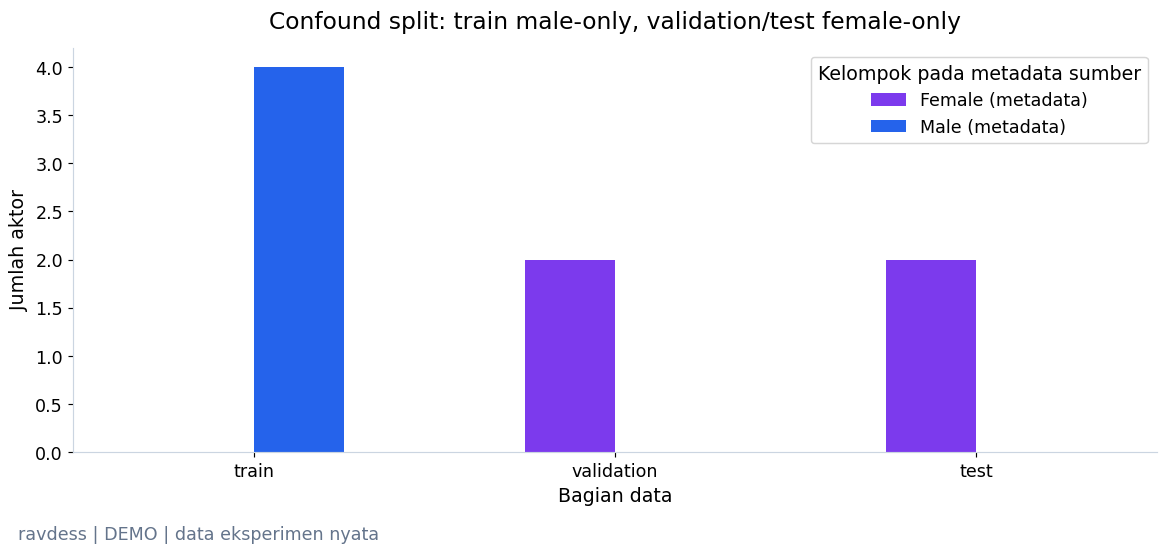

**Yang terlihat:** Keanggotaan split asli memisahkan kelompok metadata male/female sekaligus memisahkan aktor.

**Artinya:** Model mengalami domain shift yang membatasi interpretasi generalisasi dan fairness.

**Perlu diingat:** Kelompok diambil dari konvensi sumber, bukan diinferensikan dari wajah/suara; split tidak diubah sesudah melihat skor.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [7]:
fusion_data['actor_metadata_group'] = fusion_data.subject_id.astype(int).map(lambda actor:'Male (metadata)' if actor%2 else 'Female (metadata)')
split_sizes = fusion_data.groupby('split').size().to_dict()
display(fusion_data.groupby('split').agg(Klip=('sample_id','size'),Aktor=('subject_id','nunique')))
assert fusion_data.groupby('subject_id').split.nunique().max()==1
group_counts = fusion_data.groupby(['split','actor_metadata_group']).subject_id.nunique().unstack(fill_value=0).reindex(['train','validation','test'])
fig,ax = plt.subplots(layout='constrained')
group_counts.plot.bar(ax=ax,rot=0,color=[COLORS['visual'],COLORS['audio']])
ax.set(xlabel='Bagian data',ylabel='Jumlah aktor',title='Confound split: train male-only, validation/test female-only')
ax.legend(title='Kelompok pada metadata sumber')
fusion_book.show(fig,'split_dan_demografi',
                 'Keanggotaan split asli memisahkan kelompok metadata male/female sekaligus memisahkan aktor.',
                 'Model mengalami domain shift yang membatasi interpretasi generalisasi dan fairness.',
                 'Kelompok diambil dari konvensi sumber, bukan diinferensikan dari wajah/suara; split tidak diubah sesudah melihat skor.')

### 3.1 Siapa berada di setiap split, dan berapa banyak contoh per kelas?

**Motivasi:** model bisa tampak bagus pada sedikit klip sambil gagal pada orang atau kelas tertentu.
Split historis dipertahankan utuh: empat aktor train, dua validation, dua test; tidak ada aktor tumpang tindih.
Setiap aktor menyumbang 16 recording: delapan emotion, masing-masing dua pengulangan.
Metadata sumber menggunakan aktor ganjil = male dan genap = female; ini kategori metadata sumber, bukan hasil menebak dari media.
Train historis seluruhnya male, evaluasi female. Perubahan aktor dan komposisi demografi terjadi bersamaan,
sehingga selisih performa tidak bisa diatribusikan hanya pada emotion atau hanya pada demografi.

,split,Aktor sumber,actor_metadata_group,Klip,Emotion
0,test,02,Female (metadata),16,8
1,test,06,Female (metadata),16,8
2,train,01,Male (metadata),16,8
3,train,03,Male (metadata),16,8
4,train,05,Male (metadata),16,8
5,train,07,Male (metadata),16,8
6,validation,04,Female (metadata),16,8
7,validation,08,Female (metadata),16,8


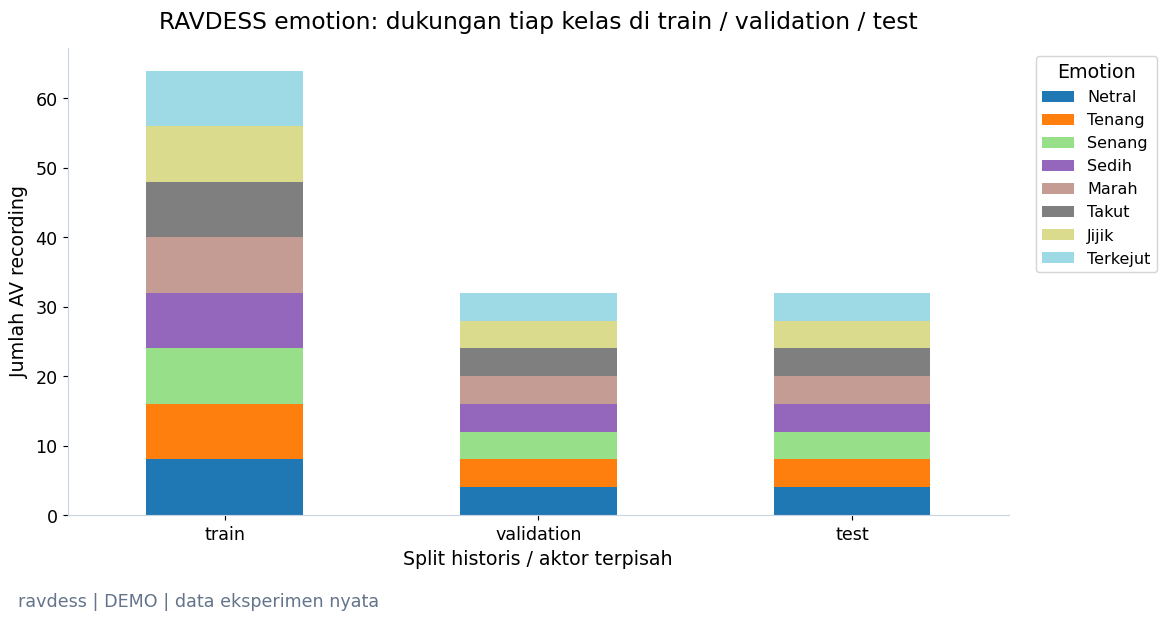

**Yang terlihat:** Setiap kelas memiliki delapan recording train, empat validation dan empat test; zero actor overlap.

**Artinya:** Hanya empat contoh test per emotion: satu kesalahan mengubah recall kelas sebesar 0,25.

**Perlu diingat:** Keseimbangan label tidak meniadakan confound aktor, demografi, intensitas dan protokol scripted speech.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

target_value,Netral,Tenang,Senang,Sedih,Marah,Takut,Jijik,Terkejut
split,,,,,,,,
train,8,8,8,8,8,8,8,8
validation,4,4,4,4,4,4,4,4
test,4,4,4,4,4,4,4,4


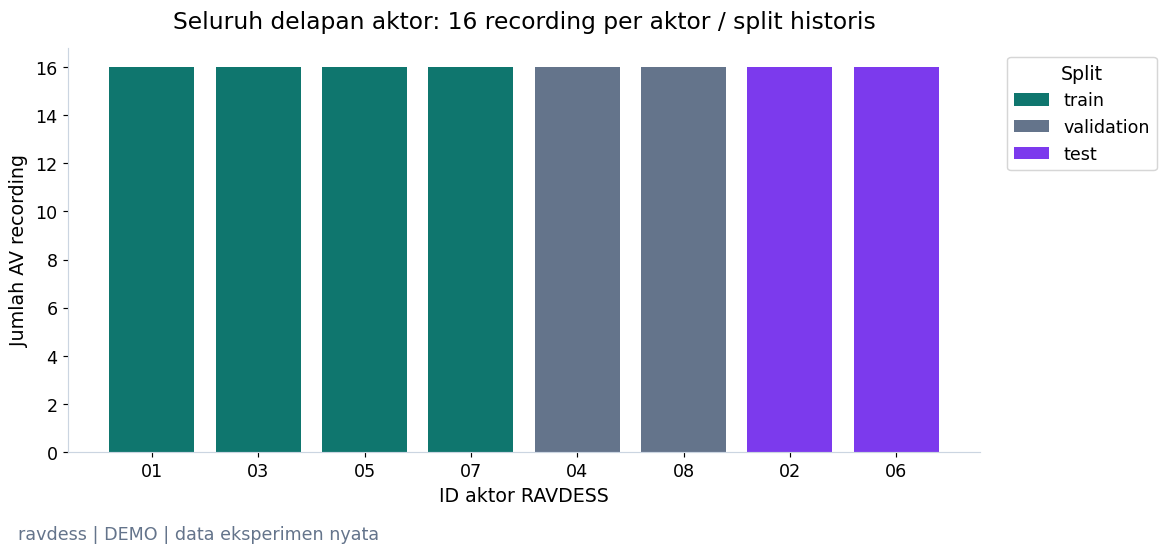

**Yang terlihat:** Distribusi recording seragam antardelapan aktor, tetapi hanya dua aktor menjadi test historis.

**Artinya:** Unit generalisasi adalah aktor, sehingga 32 klip test tidak setara 32 orang independen.

**Perlu diingat:** Subset hanya aktor 01–08; temuan tidak merepresentasikan semua aktor RAVDESS atau operator ATC.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [8]:
actor_audit = fusion_data.groupby(['split','subject_id','actor_metadata_group']).agg(
    recordings=('sample_id','size'),classes=('target_value','nunique')).reset_index()
display(actor_audit.rename(columns={'subject_id':'Aktor sumber','recordings':'Klip','classes':'Emotion'}))
assert actor_audit.groupby('subject_id').split.nunique().max()==1
split_class_counts = pd.crosstab(fusion_data.split,fusion_data.target_value).reindex(['train','validation','test'])
fig,ax = plt.subplots(figsize=(11,5.4),layout='constrained')
split_class_counts.rename(columns=EMOTIONS).plot.bar(stacked=True,ax=ax,rot=0,colormap='tab20')
ax.set(xlabel='Split historis / aktor terpisah',ylabel='Jumlah AV recording',title='RAVDESS emotion: dukungan tiap kelas di train / validation / test')
ax.legend(title='Emotion',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=11)
fusion_book.show(fig,'split_class_support',
                 'Setiap kelas memiliki delapan recording train, empat validation dan empat test; zero actor overlap.',
                 'Hanya empat contoh test per emotion: satu kesalahan mengubah recall kelas sebesar 0,25.',
                 'Keseimbangan label tidak meniadakan confound aktor, demografi, intensitas dan protokol scripted speech.')
display(split_class_counts.rename(columns=EMOTIONS))
fig,ax = plt.subplots(layout='constrained')
for partition,color in [('train',COLORS['fusion']),('validation',COLORS['secondary']),('test',COLORS['visual'])]:
    selected = actor_audit[actor_audit.split.eq(partition)]
    ax.bar(selected.subject_id.astype(str),selected.recordings,color=color,label=partition)
ax.set(xlabel='ID aktor RAVDESS',ylabel='Jumlah AV recording',title='Seluruh delapan aktor: 16 recording per aktor / split historis')
ax.legend(title='Split',loc='upper left',bbox_to_anchor=(1.02,1))
fusion_book.show(fig,'actor_recording_counts',
                 'Distribusi recording seragam antardelapan aktor, tetapi hanya dua aktor menjadi test historis.',
                 'Unit generalisasi adalah aktor, sehingga 32 klip test tidak setara 32 orang independen.',
                 'Subset hanya aktor 01–08; temuan tidak merepresentasikan semua aktor RAVDESS atau operator ATC.')

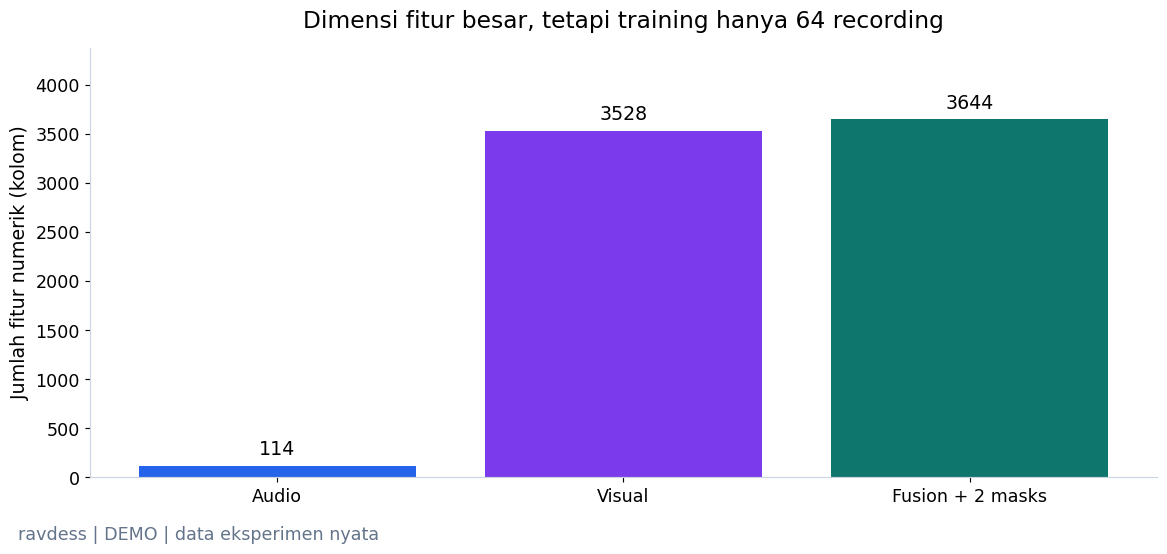

**Yang terlihat:** 3644 kolom fusion dibanding hanya 64 baris training.

**Artinya:** Banyak fitur pada sedikit sampel meningkatkan risiko overfitting; regularisasi tidak menghilangkan kebutuhan data.

**Perlu diingat:** Jumlah kolom bukan ukuran jumlah peserta atau bukti bahwa model lebih baik.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [9]:
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar(['Audio','Visual','Fusion + 2 masks'],[len(audio_columns),len(visual_columns),len(fusion_columns)],
              color=[COLORS['audio'],COLORS['visual'],COLORS['fusion']])
ax.bar_label(bars,padding=5)
ax.set(ylabel='Jumlah fitur numerik (kolom)',ylim=(0,len(fusion_columns)*1.2),
       title=f'Dimensi fitur besar, tetapi training hanya {split_sizes["train"]} recording')
fusion_book.show(fig,'dimensi_fitur',
                 f'{len(fusion_columns)} kolom fusion dibanding hanya {split_sizes["train"]} baris training.',
                 'Banyak fitur pada sedikit sampel meningkatkan risiko overfitting; regularisasi tidak menghilangkan kebutuhan data.',
                 'Jumlah kolom bukan ukuran jumlah peserta atau bukti bahwa model lebih baik.')

### 3.2 Apakah jumlah fitur sebanding dengan jumlah contoh training?

Satu **dimensi fitur** adalah satu angka input. Pada split historis hanya 64 contoh training,
sedangkan HOG wajah menghasilkan ribuan angka. Banyaknya fitur memberi model banyak cara memisahkan sedikit contoh;
pola kebetulan mudah ikut dipelajari. Standardisasi dan regularisasi membantu, tetapi tidak menambah orang baru atau membuktikan generalisasi.
Tidak ada PCA yang di-fit pada seluruh data, dan tidak ada penambahan model kompleks demi mengejar skor test.

In [10]:
dimension_audit = pd.DataFrame([
    {'Representasi':label,'Fitur':len(columns),'Training recording':int(split_sizes['train']),
     'Rasio fitur / training recording':len(columns)/split_sizes['train']}
    for label,columns in [('Audio',audio_columns),('Visual',visual_columns),('Fusion + 2 masks',fusion_columns)]])
display(dimension_audit.round(3))

,Representasi,Fitur,Training recording,Rasio fitur / training recording
0,Audio,114,64,1.781
1,Visual,3528,64,55.125
2,Fusion + 2 masks,3644,64,56.938


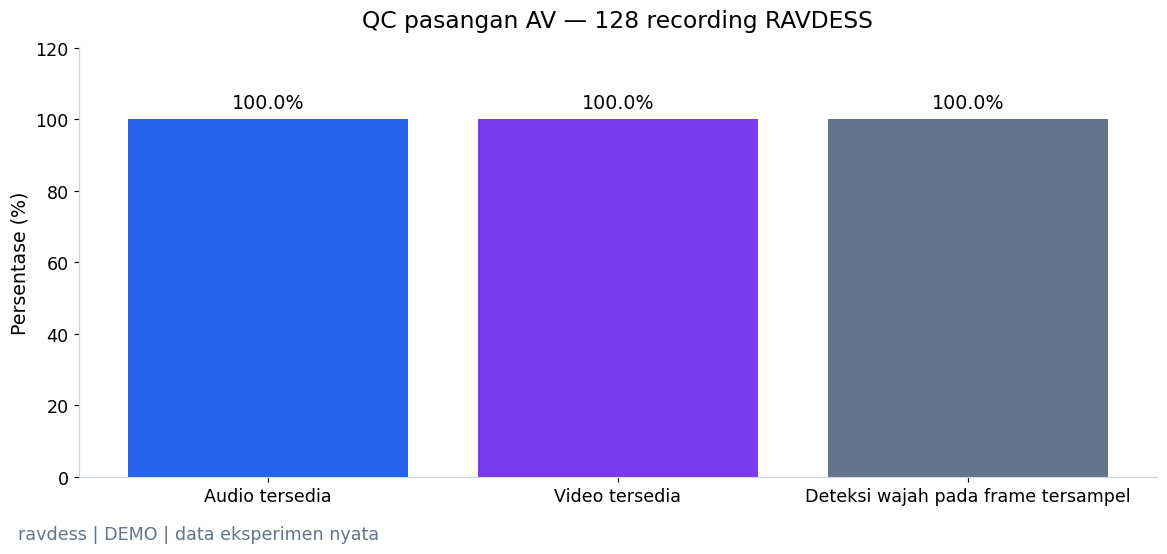

**Yang terlihat:** Audio tersedia 100.0%, video 100.0%; deteksi wajah rerata 100.0%.

**Artinya:** Ketersediaan klip dan keberhasilan deteksi per frame adalah pemeriksaan kualitas yang berbeda.

**Perlu diingat:** Persentase deteksi dirata-ratakan per klip; sampling 2 FPS bukan cakupan temporal untuk kedipan.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [11]:
availability = fusion_data[['audio_available','video_available','face_detection_rate']].mean()
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar(['Audio tersedia','Video tersedia','Deteksi wajah pada frame tersampel'],availability*100,
              color=[COLORS['audio'],COLORS['visual'],COLORS['secondary']])
ax.bar_label(bars,fmt='%.1f%%',padding=5)
ax.set(ylabel='Persentase (%)',ylim=(0,120),title=f'QC pasangan AV — {len(fusion_data)} recording RAVDESS')
fusion_book.show(fig,'qc_availability',
                 f"Audio tersedia {availability.audio_available:.1%}, video {availability.video_available:.1%}; deteksi wajah rerata {availability.face_detection_rate:.1%}.",
                 'Ketersediaan klip dan keberhasilan deteksi per frame adalah pemeriksaan kualitas yang berbeda.',
                 'Persentase deteksi dirata-ratakan per klip; sampling 2 FPS bukan cakupan temporal untuk kedipan.')

<a id="4-training-dan-evaluasi-empat-model"></a>

## 4. Training dan evaluasi empat model

Empat jalur memakai split dan label identik: Dummy mayoritas, audio, visual, dan fusion. Tiga classifier memakai **Logistic Regression**, model linear dengan regularisasi `C=1` dan bobot kelas balanced. Imputer median dan scaler dilatih di training saja.

FULL menjalankan `fit`, menghitung prediksi validation/test, menyimpan model, lalu mencocokkan prediksi hasil reload. DEMO memuat checkpoint dan memverifikasi seluruh prediksi test terhadap file tersimpan. Tidak ada skor buatan atau proses CLI tersembunyi.

### 4.1 Angka apa yang benar-benar masuk ke model?

**Early feature fusion** berarti menyambung fitur kedua modalitas sebelum classifier dilatih.
Satu row tetap mewakili **satu recording AV asli**, bukan audio dan video dari orang berbeda.
Audio merangkum statistik suara; HOG (*Histogram of Oriented Gradients*) merangkum pola tepi wajah,
bukan landmark EAR, blink duration, atau PERCLOS. Dua availability masks menyatakan ada/tidaknya modalitas.

Kita tampilkan dimensi aktual, nama kolom, beberapa nilai, serta bentuk `X` dan `y` tiap split.
ID, path, actor, demographic metadata, timestamp, dan target tidak masuk prediktor.
Nilai mentah memiliki satuan berbeda sehingga tidak adil dibandingkan besar angkanya langsung.
Imputation dan standardization berikutnya dipelajari **hanya dari 64 training clips**.

**Late fusion** berbeda: keputusan atau probabilitas dua classifier digabung setelah masing-masing dilatih.
Di sini perbandingan utama tetap empat model historis; tidak ada bobot late fusion yang dicari dari test score.

In [12]:
from IPython.display import HTML
representation_blocks = [('Audio',audio_columns),('Visual HOG',visual_columns),('Availability masks',['audio_available','video_available']),('Fusion',fusion_columns)]
display(pd.DataFrame([{'Blok':label,'Dimensi aktual':len(columns),'Nama awal':', '.join(columns[:2]),'Nama akhir':columns[-1]} for label,columns in representation_blocks]))
display(pd.DataFrame([{'Split':part,'X audio':(len(group),len(audio_columns)),'X visual':(len(group),len(visual_columns)),
                       'X fusion':(len(group),len(fusion_columns)),'y':group.target_value.shape,'Aktor':group.subject_id.nunique()}
                      for part,group in fusion_data.groupby('split')]))
display(pd.crosstab(fusion_data.split,fusion_data.target_value).rename(columns=EMOTIONS))
vector_row = fusion_data.loc[fusion_data.sample_id.eq(example_id)].iloc[0]
vector_columns = audio_columns[:4]+visual_columns[:4]+['audio_available','video_available']
display(pd.DataFrame({'Feature':vector_columns,'Nilai aktual':[float(vector_row[column]) for column in vector_columns]}))
display(HTML('<details><summary>Schema lengkap fusion: '+str(len(fusion_columns))+' prediktor</summary>'+pd.DataFrame({'Kolom':fusion_columns}).to_html(index=False)+'</details>'))
print('Satu row fusion = audio + visual dari recording yang sama + dua masks; label emotion disimpan terpisah.')

,Blok,Dimensi aktual,Nama awal,Nama akhir
0,Audio,114,"egemaps__F0semitoneFrom27.5Hz_sma3nz_amean, eg...",mfcc_12_std
1,Visual HOG,3528,"visual_hog_0000_mean, visual_hog_0001_mean",visual_hog_1763_std
2,Availability masks,2,"audio_available, video_available",video_available
3,Fusion,3644,"egemaps__F0semitoneFrom27.5Hz_sma3nz_amean, eg...",video_available


,Split,X audio,X visual,X fusion,y,Aktor
0,test,"(32, 114)","(32, 3528)","(32, 3644)","(32,)",2
1,train,"(64, 114)","(64, 3528)","(64, 3644)","(64,)",4
2,validation,"(32, 114)","(32, 3528)","(32, 3644)","(32,)",2


target_value,Netral,Tenang,Senang,Sedih,Marah,Takut,Jijik,Terkejut
split,,,,,,,,
test,4,4,4,4,4,4,4,4
train,8,8,8,8,8,8,8,8
validation,4,4,4,4,4,4,4,4


,Feature,Nilai aktual
0,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,37.177738
1,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.101609
2,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentil...,34.296551
3,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentil...,35.410973
4,visual_hog_0000_mean,0.336806
5,visual_hog_0001_mean,0.175835
6,visual_hog_0002_mean,0.255914
7,visual_hog_0003_mean,0.106086
8,audio_available,1.000000
9,video_available,1.000000


Kolom
egemaps__F0semitoneFrom27.5Hz_sma3nz_amean
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile80.0
egemaps__F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2
egemaps__F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope
egemaps__F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope


Satu row fusion = audio + visual dari recording yang sama + dua masks; label emotion disimpan terpisah.


In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
feature_sets = {'dummy_majority':audio_columns,'audio_only':audio_columns,
                'visual_only':visual_columns,'audio_visual':fusion_columns}
fusion_training = fusion_data[fusion_data.split.eq('train')]
fusion_holdout = fusion_data[~fusion_data.split.eq('train')]
if RUN_MODE=='FULL':
    fusion_run.features(fusion_data,fusion_columns,'audio-egemapsv02-mfcc13-v1; sampled-face-hog-2fps-v1')
    fusion_data[['sample_id','subject_id','target_value','source_checksum','split']].to_csv(fusion_run.file('split_manifest.csv'),index=False)
    fusion_scores,fusion_prediction_parts,fitted_models = {},[],{}
    for model_name,columns in feature_sets.items():
        model = DummyClassifier(strategy='most_frequent') if model_name=='dummy_majority' else make_pipeline(
            SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),
            LogisticRegression(C=config['fusion']['logistic_c'],class_weight='balanced',
                               max_iter=config['fusion']['max_iter'],random_state=config['seed']))
        model.fit(fusion_training[columns],fusion_training.target_value)
        save_model(fusion_run,model_name,model,columns,fusion_holdout)
        fitted_models[model_name] = model
        fusion_scores[model_name] = {'reload_verified':True,'feature_count':len(columns)}
        for partition in ['validation','test']:
            part = fusion_data[fusion_data.split.eq(partition)]
            predicted = model.predict(part[columns])
            fusion_scores[model_name][partition] = classification_metrics(part.target_value,predicted,list(EMOTIONS))
            fusion_prediction_parts.append(prediction_table(part,predicted,model_name))
    fusion_predictions = pd.concat(fusion_prediction_parts,ignore_index=True)
    fusion_predictions.to_csv(fusion_run.file('predictions/holdout_predictions.csv'),index=False)
    fusion_metrics = metrics_base(fusion_run,fusion_scores,split_sizes,{str(k):v for k,v in EMOTIONS.items()},'dummy_majority')
else:
    fusion_predictions = pd.read_csv(fusion_run.path / 'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    for model_name in feature_sets:
        verify_cached_predictions(fusion_run,fusion_data[fusion_data.split.eq('test')],fusion_predictions,model_name)

**audio_only:** X_train (64, 114); X_test (32, 114); missing raw train 0.

,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,egemaps__loudness_sma3_pctlrange0-2,egemaps__mfcc1_sma3_amean,egemaps__jitterLocal_sma3nz_amean,egemaps__logRelF0-H1-H2_sma3nz_stddevNorm,egemaps__F1amplitudeLogRelF0_sma3nz_stddevNorm,egemaps__F3frequency_sma3nz_amean
0,24.5792,93.1979,0.1249,12.7215,0.0252,1.2732,-0.4971,2567.9417
1,25.0815,39.2871,0.1263,13.0104,0.0189,0.8680,-0.5341,2585.0442


,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,egemaps__loudness_sma3_pctlrange0-2,egemaps__mfcc1_sma3_amean,egemaps__jitterLocal_sma3nz_amean,egemaps__logRelF0-H1-H2_sma3nz_stddevNorm,egemaps__F1amplitudeLogRelF0_sma3nz_stddevNorm,egemaps__F3frequency_sma3nz_amean
0,-0.9751,0.0396,-0.5021,-0.3021,0.1203,-0.1415,0.3383,-0.8935
1,-0.8483,-0.4602,-0.4910,-0.1576,-0.4980,-0.2172,-0.0618,-0.6619


**visual_only:** X_train (64, 3528); X_test (32, 3528); missing raw train 0.

,visual_hog_0000_mean,visual_hog_0235_mean,visual_hog_0470_mean,visual_hog_0705_mean,visual_hog_0940_mean,visual_hog_1175_mean,visual_hog_1410_mean,visual_hog_1645_mean
0,0.4150,0.1556,0.0232,0.1259,0.3391,0.1080,0.1326,0.0566
1,0.4174,0.0585,0.0015,0.0571,0.3365,0.1092,0.1093,0.0398


,visual_hog_0000_mean,visual_hog_0235_mean,visual_hog_0470_mean,visual_hog_0705_mean,visual_hog_0940_mean,visual_hog_1175_mean,visual_hog_1410_mean,visual_hog_1645_mean
0,0.8620,2.2869,0.2481,-1.4051,0.8438,-1.0599,1.0723,-0.4983
1,0.8947,-0.2074,-1.0942,-2.5374,0.7835,-1.0388,0.5179,-0.9269


**audio_visual:** X_train (64, 3644); X_test (32, 3644); missing raw train 0.

,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,visual_hog_0128_mean,visual_hog_0371_mean,visual_hog_0614_mean,visual_hog_0857_mean,visual_hog_1100_mean,visual_hog_1343_mean,visual_hog_1586_mean
0,24.5792,0.0410,0.0942,0.0365,0.0889,0.1623,0.0979,0.0798
1,25.0815,0.0623,0.0771,0.0311,0.0952,0.1769,0.0924,0.0577


,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,visual_hog_0128_mean,visual_hog_0371_mean,visual_hog_0614_mean,visual_hog_0857_mean,visual_hog_1100_mean,visual_hog_1343_mean,visual_hog_1586_mean
0,-0.9751,-0.5585,0.3672,0.4855,-0.5587,0.8880,0.7009,0.1205
1,-0.8483,0.1196,0.0496,0.1597,-0.4071,1.0929,0.5727,-0.3122


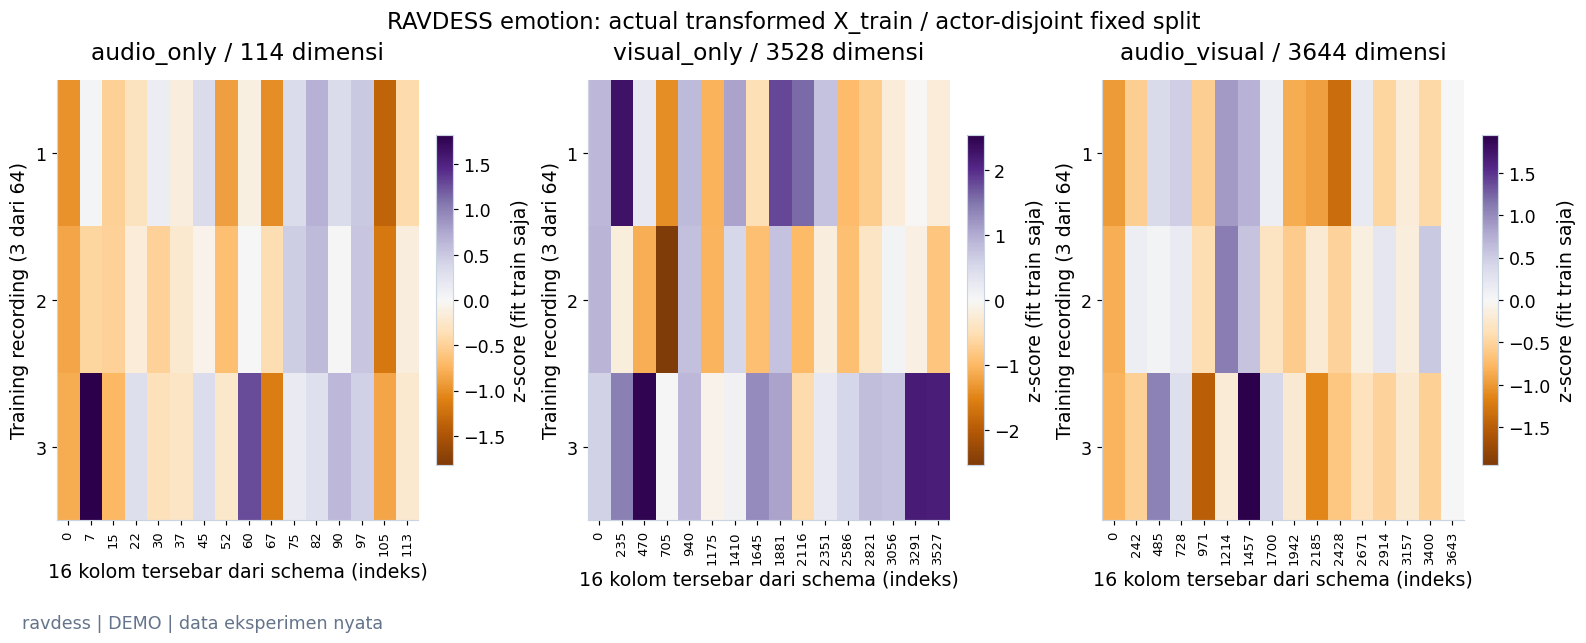

**Yang terlihat:** Tiga training rows memperlihatkan angka yang diteruskan ke classifier setelah imputation dan scaling.

**Artinya:** Posisi kolom mengikuti schema masing-masing; concatenation menambah informasi sekaligus dimensionality.

**Perlu diingat:** Subset kolom ditampilkan agar terbaca; nilai z besar bukan bukti fitur penting atau pola kausal.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED features; FRESH checkpoint inference.*

,feature,raw,transformed
0,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,37.1777,2.2059
242,visual_hog_0128_mean,0.0897,0.9939
485,visual_hog_0371_mean,0.0644,-0.1871
728,visual_hog_0614_mean,0.0129,-0.9426
971,visual_hog_0857_mean,0.0656,-1.1216
1214,visual_hog_1100_mean,0.0173,-1.1465
1457,visual_hog_1343_mean,0.1003,0.7568
1700,visual_hog_1586_mean,0.0266,-0.9214
1942,visual_hog_0064_std,0.0231,-0.3068
2185,visual_hog_0307_std,0.0475,-0.0690


In [14]:
import joblib
input_views = {}
fusion_testing = fusion_data[fusion_data.split.eq('test')]
for model_name in ['audio_only','visual_only','audio_visual']:
    bundle = joblib.load(fusion_run.path/f'models/{model_name}.joblib')
    input_views[model_name] = inspect_model_input(bundle['model'],fusion_training,fusion_testing,bundle['feature_columns'])
    view = input_views[model_name]
    display(Markdown(f"**{model_name}:** X_train {view['X_train_shape']}; X_test {view['X_test_shape']}; missing raw train {view['raw_missing_cells']}."))
    display(view['raw_preview'].iloc[:2,:8].round(4))
    display(view['transformed_preview'].iloc[:2,:8].round(4))
fig,axes = plt.subplots(1,3,figsize=(15,5.6),layout='constrained')
for axis,model_name in zip(axes,['audio_only','visual_only','audio_visual']):
    view = input_views[model_name]
    values = view['transformed_preview'].to_numpy(float)
    limit = max(1.,float(np.abs(values).max()))
    image = axis.imshow(values,aspect='auto',cmap='PuOr',vmin=-limit,vmax=limit)
    axis.set(title=f'{model_name} / {len(view["columns"])} dimensi',xlabel='16 kolom tersebar dari schema (indeks)',ylabel='Training recording (3 dari 64)',
             xticks=range(len(view['selected_indices'])),xticklabels=view['selected_indices'],yticks=range(3),yticklabels=[1,2,3])
    axis.tick_params(axis='x',rotation=90,labelsize=9)
    fig.colorbar(image,ax=axis,label='z-score (fit train saja)',shrink=.75)
fig.suptitle('RAVDESS emotion: actual transformed X_train / actor-disjoint fixed split')
fusion_book.show(fig,'fusion_actual_training_matrices',
                 'Tiga training rows memperlihatkan angka yang diteruskan ke classifier setelah imputation dan scaling.',
                 'Posisi kolom mengikuti schema masing-masing; concatenation menambah informasi sekaligus dimensionality.',
                 'Subset kolom ditampilkan agar terbaca; nilai z besar bukan bukti fitur penting atau pola kausal.',origin=source_state)
# Full source vector stays local; the public preview contains a small numeric subset only.
full_fusion_vector = input_views['audio_visual']['example_vector']
display(full_fusion_vector.iloc[np.unique(np.linspace(0,len(full_fusion_vector)-1,16,dtype=int))].round(4))

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.027778,0.125,0.125
audio_only,0.311601,0.375,0.375
visual_only,0.279657,0.34375,0.34375
audio_visual,0.454899,0.5,0.5


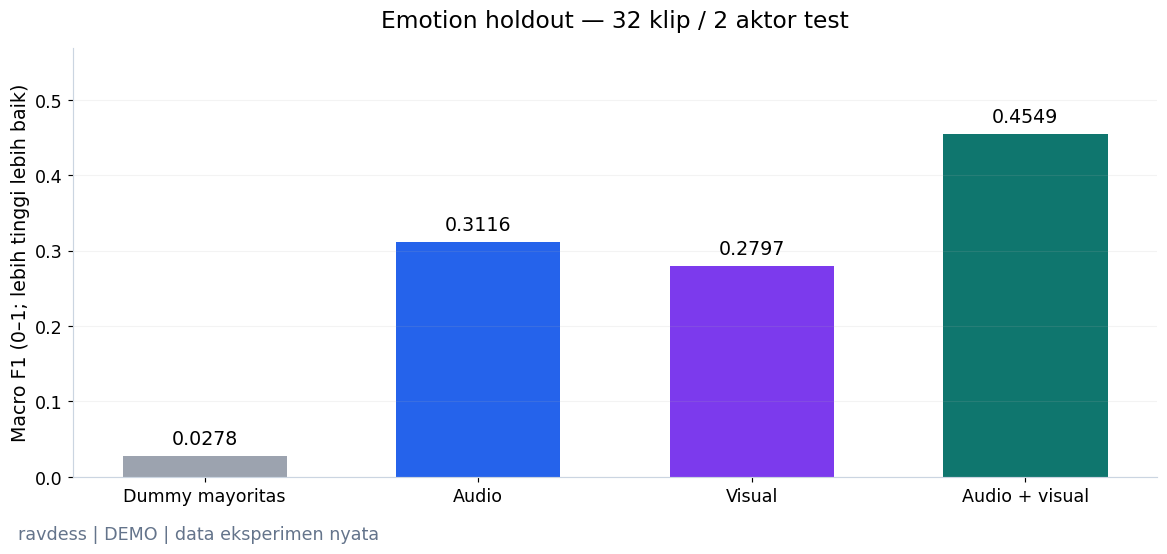

**Yang terlihat:** Fusion F1 0.4549; audio 0.3116; visual 0.2797.

**Artinya:** Pada split kecil yang sama, kita dapat membandingkan empat jalur model secara langsung.

**Perlu diingat:** Dua aktor test dan demographic shift tidak mendukung klaim keunggulan umum atau signifikansi populasi.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [15]:
fusion_test_scores = {name:value['test'] for name,value in fusion_metrics['models'].items()}
display(pd.DataFrame(fusion_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
fig = model_bars(fusion_test_scores,'macro_f1',f'Emotion holdout — {split_sizes["test"]} klip / 2 aktor test',
                 'Macro F1 (0–1; lebih tinggi lebih baik)',COLORS['fusion'])
fusion_book.show(fig,'perbandingan_model_emotion',
                 f"Fusion F1 {fusion_test_scores['audio_visual']['macro_f1']:.4f}; audio {fusion_test_scores['audio_only']['macro_f1']:.4f}; visual {fusion_test_scores['visual_only']['macro_f1']:.4f}.",
                 'Pada split kecil yang sama, kita dapat membandingkan empat jalur model secara langsung.',
                 'Dua aktor test dan demographic shift tidak mendukung klaim keunggulan umum atau signifikansi populasi.')

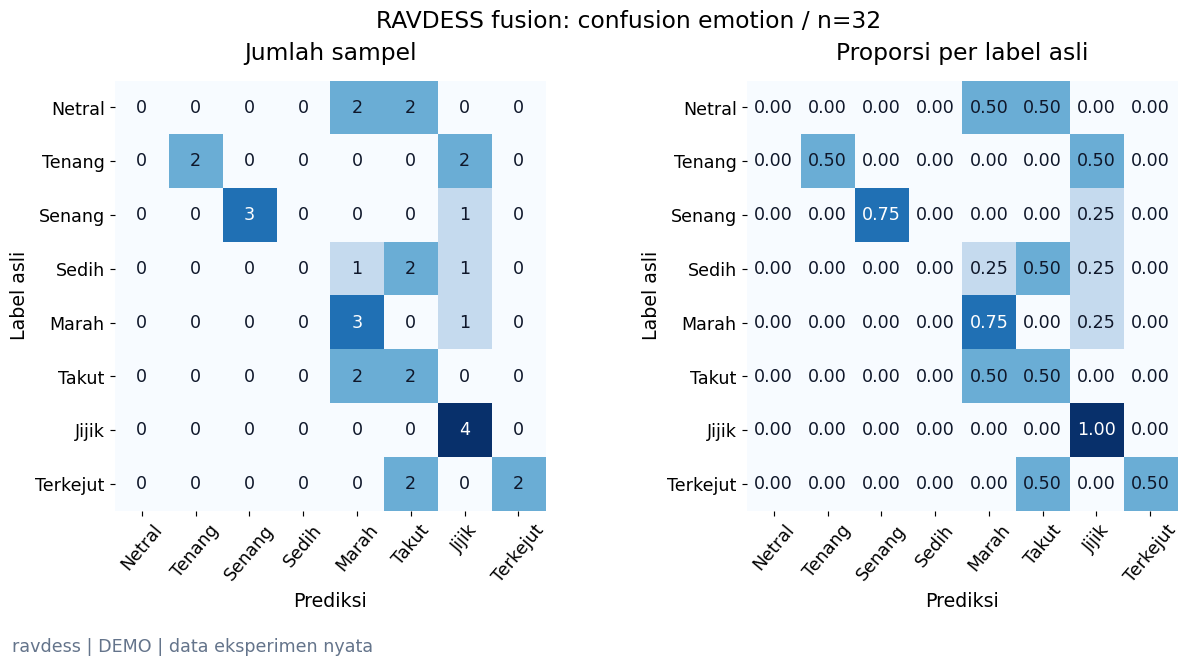

**Yang terlihat:** Sebanyak 16/32 recording diklasifikasikan benar oleh fusion.

**Artinya:** Sel di luar diagonal menunjukkan jenis emosi yang tertukar; warna dinormalisasi per label pada panel kanan.

**Perlu diingat:** Tiap kelas test hanya memiliki empat sampel; satu kesalahan mengubah recall sebesar 0,25.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [16]:
fusion_result = fusion_test_scores['audio_visual']
fig = confusion_pair(fusion_result,list(EMOTIONS.values()),f'RAVDESS fusion: confusion emotion / n={split_sizes["test"]}')
fusion_book.show(fig,'confusion_emotion',
                 f"Sebanyak {np.trace(fusion_result['confusion_matrix'])}/{split_sizes['test']} recording diklasifikasikan benar oleh fusion.",
                 'Sel di luar diagonal menunjukkan jenis emosi yang tertukar; warna dinormalisasi per label pada panel kanan.',
                 'Tiap kelas test hanya memiliki empat sampel; satu kesalahan mengubah recall sebesar 0,25.')

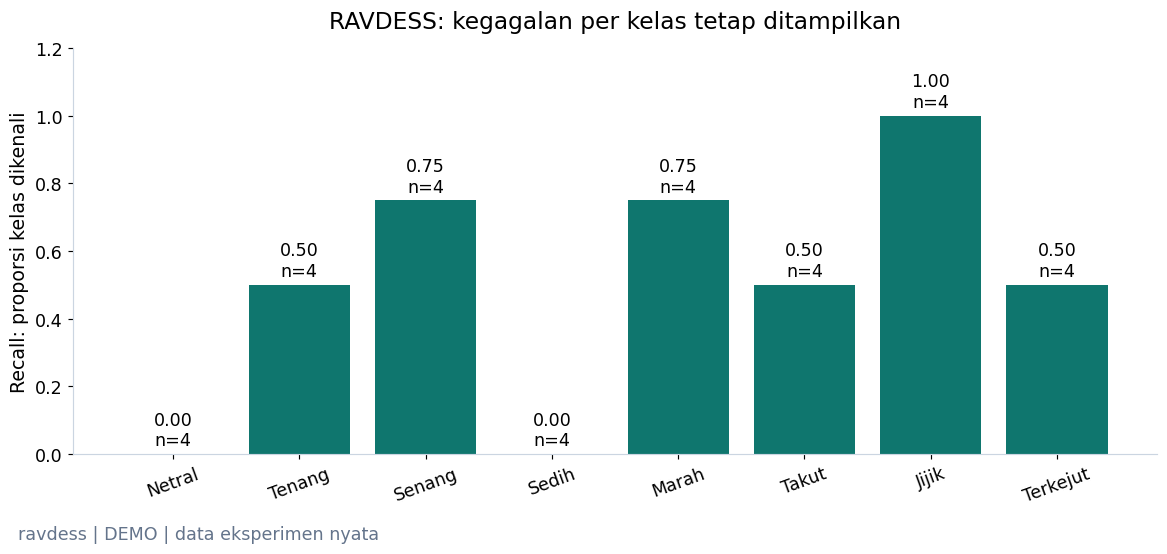

**Yang terlihat:** Kelas dengan recall nol: Netral, Sedih.

**Artinya:** Skor rata-rata belum menjamin semua kelas dikenali; error perlu dilihat per kelas.

**Perlu diingat:** Support kecil membuat perbedaan recall tidak stabil; emotion tetap berbeda dari fatigue.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

,Contoh,Label asli,Prediksi
224,contoh-61881241,Netral,Marah
225,contoh-1b850e2c,Netral,Marah
230,contoh-abfc9b36,Sedih,Marah
231,contoh-a502433b,Sedih,Jijik
234,contoh-82fd7698,Takut,Marah
235,contoh-f74e9b43,Takut,Marah


In [17]:
fig = recall_chart(fusion_result,list(EMOTIONS.values()),'RAVDESS: kegagalan per kelas tetap ditampilkan',COLORS['fusion'])
zero_recall = [EMOTIONS[label] for label in EMOTIONS if fusion_result['classification_report'][str(label)]['recall']==0]
fusion_book.show(fig,'recall_emotion',
                 f'Kelas dengan recall nol: {", ".join(zero_recall) if zero_recall else "tidak ada pada run ini"}.',
                 'Skor rata-rata belum menjamin semua kelas dikenali; error perlu dilihat per kelas.',
                 'Support kecil membuat perbedaan recall tidak stabil; emotion tetap berbeda dari fatigue.')
emotion_errors = public_errors(fusion_predictions,'audio_visual')
for column in ['Label asli','Prediksi']:
    emotion_errors[column] = emotion_errors[column].map(EMOTIONS)
display(emotion_errors)

<a id="5-modalitas-hilang-dan-inference-heldout"></a>

## 5. Modalitas hilang dan inference heldout

**Ablation** menghilangkan satu sumber informasi untuk memeriksa perubahan perilaku model. Di sini semua fitur audio atau semua fitur visual test diberi `NaN`, dan mask ketersediaan dimatikan. Median pengganti tetap berasal dari training.

Ini stress test saat inference; model **tidak dilatih untuk robust terhadap modalitas hilang**. Kita tidak mengganti nilai hilang dengan angka nol yang dianggap sinyal asli.

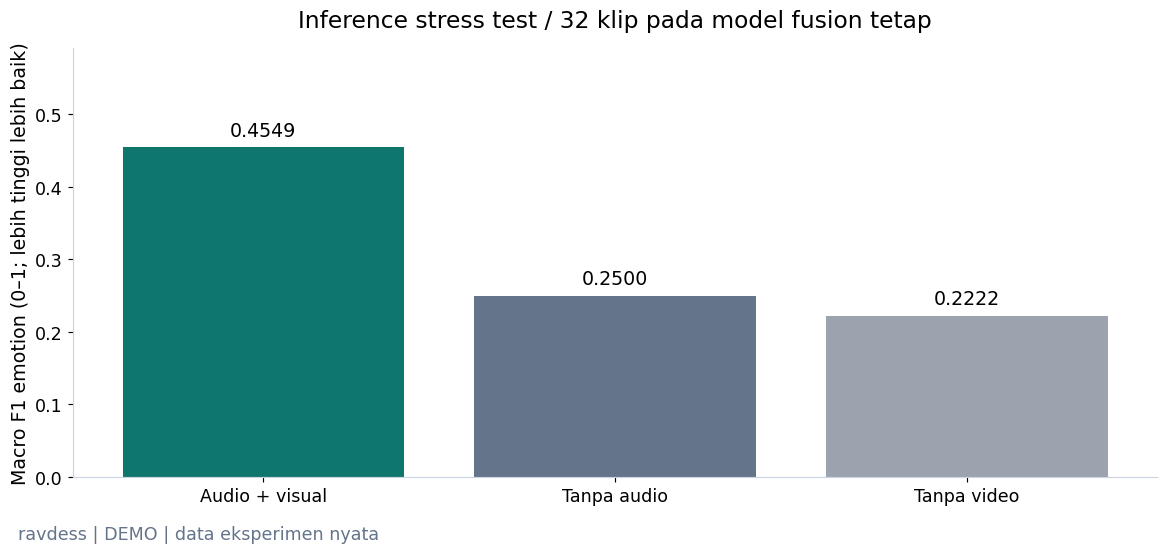

**Yang terlihat:** F1 lengkap 0.4549, tanpa audio 0.2500, tanpa video 0.2222.

**Artinya:** Perbedaan mengukur respons model tetap terhadap gangguan input pada subset ini.

**Perlu diingat:** Ini bukan hasil training missing-modality, bukan jaminan robust di lingkungan ATC.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED; inference dihitung ulang.*

In [18]:
import joblib
fusion_test = fusion_data[fusion_data.split.eq('test')]
fusion_bundle = joblib.load(fusion_run.path / 'models/audio_visual.joblib')
ablation_scores = {}
for modality,columns in [('audio',audio_columns),('video',visual_columns)]:
    masked = fusion_test[fusion_columns].copy()
    masked[columns] = np.nan
    masked[f'{modality}_available'] = False
    predicted = fusion_bundle['model'].predict(masked)
    ablation_scores[f'all_{modality}_missing'] = classification_metrics(fusion_test.target_value,predicted,list(EMOTIONS))
if RUN_MODE=='FULL':
    fusion_metrics['models']['audio_visual']['missing_modality_test'] = ablation_scores
else:
    for scenario in ablation_scores:
        np.testing.assert_allclose(ablation_scores[scenario]['macro_f1'],
            fusion_metrics['models']['audio_visual']['missing_modality_test'][scenario]['macro_f1'])
fig,ax = plt.subplots(layout='constrained')
ablation_values = [fusion_result['macro_f1'],ablation_scores['all_audio_missing']['macro_f1'],ablation_scores['all_video_missing']['macro_f1']]
bars = ax.bar(['Audio + visual','Tanpa audio','Tanpa video'],ablation_values,
              color=[COLORS['fusion'],COLORS['secondary'],COLORS['baseline']])
ax.bar_label(bars,fmt='%.4f',padding=5)
ax.set(ylabel='Macro F1 emotion (0–1; lebih tinggi lebih baik)',ylim=(0,max(ablation_values)*1.3),
       title=f'Inference stress test / {len(fusion_test)} klip pada model fusion tetap')
fusion_book.show(fig,'ablation_modalitas',
                 f'F1 lengkap {ablation_values[0]:.4f}, tanpa audio {ablation_values[1]:.4f}, tanpa video {ablation_values[2]:.4f}.',
                 'Perbedaan mengukur respons model tetap terhadap gangguan input pada subset ini.',
                 'Ini bukan hasil training missing-modality, bukan jaminan robust di lingkungan ATC.')

### Inference langsung dari checkpoint pada contoh holdout

Contoh berikut dipilih deterministik dari bagian test sebelum training, bukan dipilih karena prediksinya benar. Fitur satu klip berasal dari ekstraksi asli: dihitung ulang pada FULL/privat, atau dibaca dari cache terverifikasi pada DEMO publik. Ketiga checkpoint dimuat lagi dan label asli ditampilkan agar kegagalan juga terlihat. Tidak ada confidence score yang diklaim sebagai jaminan.

Pada DEMO publik, ekstraksi media tidak diulang: input berasal dari cache asli yang checksum-nya diverifikasi. Prediksi checkpoint tetap dihitung ulang.

In [19]:
live_table = pd.DataFrame([live_paired_features])
inference_rows = []
for model_name in ['audio_only','visual_only','audio_visual']:
    bundle = joblib.load(fusion_run.path / f'models/{model_name}.joblib')
    assert bundle['target']=='emotion'
    prediction = int(bundle['model'].predict(live_table[bundle['feature_columns']])[0])
    inference_rows.append({'Model':model_name,'Contoh':pseudonym(example_id),'Target':'emotion',
                            'Label asli':EMOTIONS[int(heldout_source.target_value)],'Prediksi':EMOTIONS[prediction],
                            'Benar':prediction==int(heldout_source.target_value)})
display(pd.DataFrame(inference_rows))

,Model,Contoh,Target,Label asli,Prediksi,Benar
0,audio_only,contoh-61881241,emotion,Netral,Terkejut,False
1,visual_only,contoh-61881241,emotion,Netral,Marah,False
2,audio_visual,contoh-61881241,emotion,Netral,Marah,False


## 5.1 Audit error historis: semua kelas, semua aktor, contoh deterministik

Precision menjawab berapa banyak prediksi suatu emotion yang benar; recall menjawab berapa banyak contoh emotion asli yang ditemukan.
F1 merangkum keduanya dan support adalah jumlah contoh asli. Tabel berikut memakai test historis yang sama dengan skor sebelumnya.
Contoh kasus dipilih sebagai delapan sample ID test pertama menurut urutan leksikografis, mencakup keberhasilan dan kegagalan apa pun yang muncul;
bukan dipilih karena fusion tampak bagus. ID contoh di-hash untuk tampilan publik, tanpa audio atau wajah.

In [20]:
from atc_fatigue.research.data import actor_metric_table
report_rows = []
for name,score in fusion_test_scores.items():
    for label,description in EMOTIONS.items():
        report_rows.append({'Model':name,'Emotion':description,**score['classification_report'][str(label)]})
display(pd.DataFrame(report_rows)[['Model','Emotion','precision','recall','f1-score','support']].round(3))
historical_predictions = fusion_predictions[fusion_predictions.split.eq('test')]
historical_actor_scores = actor_metric_table(historical_predictions,list(EMOTIONS))
display(historical_actor_scores.rename(columns={'subject_id':'Aktor test historis'}).round(4))
case_ids = sorted(fusion_test.sample_id)[:8]
cases = historical_predictions[historical_predictions.sample_id.isin(case_ids)].pivot(index='sample_id',columns='model',values='prediction')
truths = historical_predictions.drop_duplicates('sample_id').set_index('sample_id').truth
case_display = pd.DataFrame({'Contoh':[pseudonym(value) for value in cases.index],
                             'Label asli':truths.reindex(cases.index).map(EMOTIONS).values})
for name in ['audio_only','visual_only','audio_visual']:
    case_display[name] = cases[name].map(EMOTIONS).values
case_display['Semua model setuju'] = cases[['audio_only','visual_only','audio_visual']].nunique(axis=1).eq(1).values
case_display['Fusion benar'] = cases.audio_visual.eq(truths.reindex(cases.index)).values
display(case_display)
display(Markdown('Kesepakatan model tidak menjamin benar. Kasus ini menjelaskan pola prediksi saja; tanpa review media dan anotasi tambahan, penyebab error tidak dapat disimpulkan.'))

,Model,Emotion,precision,recall,f1-score,support
0,dummy_majority,Netral,0.125,1.00,0.222,4.0
1,dummy_majority,Tenang,0.000,0.00,0.000,4.0
2,dummy_majority,Senang,0.000,0.00,0.000,4.0
3,dummy_majority,Sedih,0.000,0.00,0.000,4.0
4,dummy_majority,Marah,0.000,0.00,0.000,4.0
5,dummy_majority,Takut,0.000,0.00,0.000,4.0
6,dummy_majority,Jijik,0.000,0.00,0.000,4.0
7,dummy_majority,Terkejut,0.000,0.00,0.000,4.0
8,audio_only,Netral,0.000,0.00,0.000,4.0
9,audio_only,Tenang,0.000,0.00,0.000,4.0


,model,Aktor test historis,recordings,macro_f1,balanced_accuracy,accuracy
0,audio_only,02,16,0.2232,0.3125,0.3125
1,audio_only,06,16,0.3770,0.4375,0.4375
2,audio_visual,02,16,0.5306,0.6250,0.6250
3,audio_visual,06,16,0.2792,0.3750,0.3750
4,dummy_majority,02,16,0.0278,0.1250,0.1250
5,dummy_majority,06,16,0.0278,0.1250,0.1250
6,visual_only,02,16,0.3512,0.5000,0.5000
7,visual_only,06,16,0.1333,0.1875,0.1875


,Contoh,Label asli,audio_only,visual_only,audio_visual,Semua model setuju,Fusion benar
0,contoh-61881241,Netral,Terkejut,Marah,Marah,False,False
1,contoh-c5804e39,Netral,Jijik,Takut,Takut,False,False
2,contoh-1b850e2c,Netral,Terkejut,Marah,Marah,False,False
3,contoh-dfffc26f,Netral,Takut,Takut,Takut,True,False
4,contoh-3f686a8c,Tenang,Takut,Tenang,Tenang,False,True
5,contoh-8223bd25,Tenang,Jijik,Jijik,Jijik,True,False
6,contoh-bd6b13e7,Tenang,Takut,Tenang,Tenang,False,True
7,contoh-7f2519c6,Tenang,Takut,Jijik,Jijik,False,False


Kesepakatan model tidak menjamin benar. Kasus ini menjelaskan pola prediksi saja; tanpa review media dan anotasi tambahan, penyebab error tidak dapat disimpulkan.

### 5.1a Walkthrough satu prediksi, lalu satu kegagalan

Kita pilih recording test pertama menurut ID, **sebelum melihat skor**, untuk perjalanan sembilan langkah.
Setelah itu tampilkan kesalahan fusion pertama menurut aturan yang sama jika tersedia. Kasus gagal sengaja
terlihat, tanpa mengganti contoh utama dengan yang paling bagus.

1. Ambil satu genuine paired AV recording dan label emotion aslinya.
2. Periksa kedua stream, durasi, offset timestamp, dan status ekstraksinya.
3. Tampilkan subset vektor audio aktual.
4. Tampilkan subset vektor visual aktual.
5. Sambungkan kedua vektor dan dua masks sesuai urutan schema.
6. Hitung prediksi audio-only dari checkpoint.
7. Hitung prediksi visual-only dari checkpoint.
8. Hitung prediksi early fusion dari checkpoint.
9. Bandingkan semuanya dengan ground truth emotion.

Tidak ada reconstruction audio/wajah di output publik. Metadata dan angka fitur yang ditampilkan berasal
langsung dari source checksum, extraction cache, dan model pada run ini.

**Step 1–2 · contoh-61881241 · ground truth: Netral**

,Audio durasi (s),Video durasi (s),Offset audio−video (s),Audio tersedia,Video tersedia,Genuine paired,Sumber
0,3.648,3.636967,0.0,True,True,True,REAL / CACHED features; FRESH checkpoint infer...


,Step,Feature,Nilai aktual
0,3 / audio,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,37.17774
1,3 / audio,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.10161
2,3 / audio,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentil...,34.29655
3,3 / audio,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentil...,35.41097
4,4 / visual,visual_hog_0000_mean,0.33681
5,4 / visual,visual_hog_0001_mean,0.17584
6,4 / visual,visual_hog_0002_mean,0.25591
7,4 / visual,visual_hog_0003_mean,0.10609
8,5 / masks,audio_available,1.00000
9,5 / masks,video_available,1.00000


,Contoh,Ground truth,Dimensi concatenation,Step 6 / audio_only,Step 7 / visual_only,Step 8 / audio_visual,Step 9 / fusion benar
0,contoh-61881241,Netral,3644,Terkejut,Marah,Marah,False


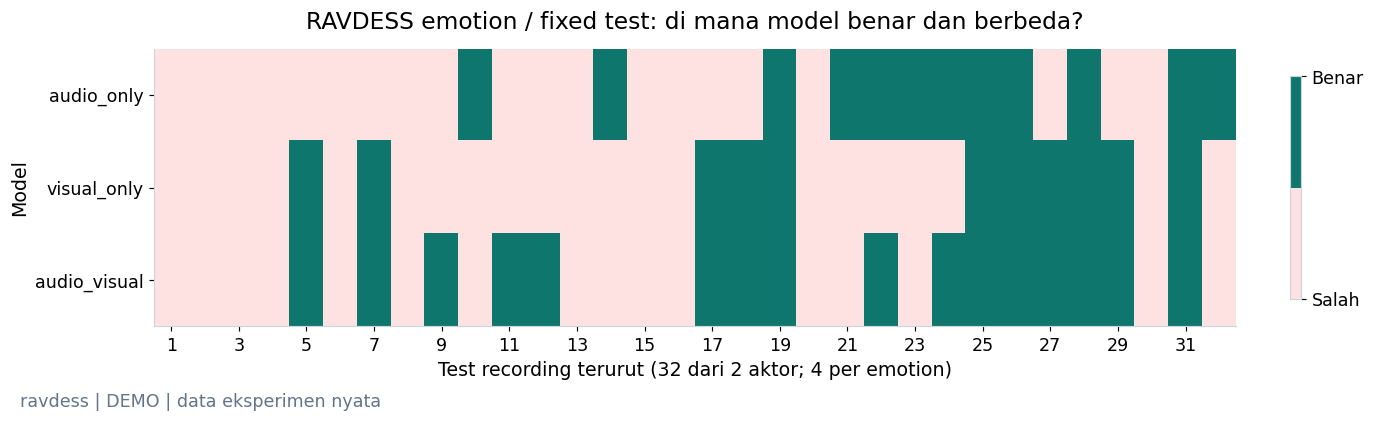

**Yang terlihat:** Fusion salah pada 16/32 recording; semua recording test ditampilkan.

**Artinya:** Baris berbeda menunjukkan informasi modalitas dapat membantu atau menyesatkan pada klip yang sama.

**Perlu diingat:** Klip dalam satu aktor tidak independen; diagram error tidak menunjukkan penyebab dan bukan fatigue detection.

*Sumber: `20261023T104859625424Z_seed42_cce30b` · REAL / CACHED features; FRESH checkpoint inference.*

In [21]:
comparison = historical_predictions.pivot(index='sample_id',columns='model',values='prediction').sort_index()
comparison['truth'] = truths.reindex(comparison.index)
failed = comparison.index[comparison.audio_visual.ne(comparison.truth)].tolist()
walkthrough_ids = [sorted(fusion_testing.sample_id)[0]]
if failed and failed[0] not in walkthrough_ids:walkthrough_ids.append(failed[0])
walkthrough_rows = []
for sample_id in walkthrough_ids:
    recording = fusion_testing.loc[fusion_testing.sample_id.eq(sample_id)].iloc[0]
    audio_vector = recording[audio_columns].to_numpy(float)
    visual_vector = recording[visual_columns].to_numpy(float)
    concatenated = np.concatenate([audio_vector,visual_vector,recording[['audio_available','video_available']].to_numpy(float)])
    np.testing.assert_array_equal(concatenated,recording[fusion_columns].to_numpy(float))
    display(Markdown(f'**Step 1–2 · {pseudonym(sample_id)} · ground truth: {EMOTIONS[int(recording.target_value)]}**'))
    display(pd.DataFrame([{'Audio durasi (s)':recording.duration_seconds,'Video durasi (s)':recording.video_duration_ms/1000,
        'Offset audio−video (s)':recording.stream_offset_seconds,'Audio tersedia':recording.audio_available,
        'Video tersedia':recording.video_available,'Genuine paired':recording.paired_recording_verified,'Sumber':source_state}]))
    subset = audio_columns[:4]+visual_columns[:4]+['audio_available','video_available']
    display(pd.DataFrame({'Step':['3 / audio']*4+['4 / visual']*4+['5 / masks']*2,'Feature':subset,'Nilai aktual':recording[subset].to_numpy(float)}).round(5))
    row = {'Contoh':pseudonym(sample_id),'Ground truth':EMOTIONS[int(recording.target_value)],'Dimensi concatenation':len(concatenated)}
    for step,model_name in enumerate(['audio_only','visual_only','audio_visual'],start=6):
        bundle = joblib.load(fusion_run.path/f'models/{model_name}.joblib')
        predicted = int(bundle['model'].predict(pd.DataFrame([recording])[bundle['feature_columns']])[0])
        assert predicted == int(comparison.loc[sample_id,model_name])
        row[f'Step {step} / {model_name}'] = EMOTIONS[predicted]
    row['Step 9 / fusion benar'] = int(comparison.loc[sample_id,'audio_visual'])==int(recording.target_value)
    walkthrough_rows.append(row)
display(pd.DataFrame(walkthrough_rows))
model_order = ['audio_only','visual_only','audio_visual']
error_status = np.array([comparison[name].eq(comparison.truth).to_numpy(int) for name in model_order])
fig,axis = plt.subplots(figsize=(13,3.6),layout='constrained')
from matplotlib.colors import ListedColormap
image = axis.imshow(error_status,aspect='auto',vmin=0,vmax=1,cmap=ListedColormap(['#FEE2E2',COLORS['fusion']]))
axis.set(yticks=range(3),yticklabels=model_order,xticks=range(0,len(comparison),2),xticklabels=np.arange(1,len(comparison)+1,2),
         xlabel='Test recording terurut (32 dari 2 aktor; 4 per emotion)',ylabel='Model',title='RAVDESS emotion / fixed test: di mana model benar dan berbeda?')
bar = fig.colorbar(image,ax=axis,ticks=[0,1],shrink=.8);bar.ax.set_yticklabels(['Salah','Benar'])
fusion_book.show(fig,'fusion_recording_error_map',
                 f"Fusion salah pada {int((error_status[2]==0).sum())}/{len(comparison)} recording; semua recording test ditampilkan.",
                 'Baris berbeda menunjukkan informasi modalitas dapat membantu atau menyesatkan pada klip yang sama.',
                 'Klip dalam satu aktor tidak independen; diagram error tidak menunjukkan penyebab dan bukan fatigue detection.',origin=source_state)

## 5.2 Sensitivity analysis: Leave-One-Actor-Out (LOAO)

**Pertanyaan:** apakah kesan bahwa fusion lebih baik tetap konsisten ketika orang yang ditahan berganti?
LOAO melatih pada tujuh aktor (112 klip) dan menguji satu aktor (16 klip), diulang untuk kedelapan aktor.
Ini menghindari train male-only historis: tiap fold training memuat kedua kelompok metadata, dengan heldout satu aktor.
Setiap kelas tersedia dalam setiap fold. Tidak ada overlap aktor train/test dalam satu evaluasi.

**Status exploratory, bukan test baru yang belum pernah disentuh.** Seluruh delapan aktor sudah hadir pada pengembangan subset sebelumnya.
Kita tidak memilih split dengan skor terbaik, tidak memakai test untuk tuning, dan tidak mengganti benchmark historis.
Hasil LOAO membandingkan empat model pada **fold dan populasi yang sama**. Skornya tidak dibandingkan langsung sebagai kenaikan
terhadap test historis dua aktor karena ukuran training dan populasi evaluasinya berbeda.

Inputnya fitur AV asli yang sudah diekstrak, bukan pasangan antar-dataset. Setiap fold membuat pipeline median/scaler baru,
di-fit hanya pada training fold. Model tetap Dummy dan Logistic Regression C=1; seluruh 32 checkpoint dan prediksi fold disimpan.

In [22]:
from sklearn.model_selection import LeaveOneGroupOut
loao_data = fusion_data.drop(columns=['split']).copy()
loao_folds = list(LeaveOneGroupOut().split(loao_data,groups=loao_data.subject_id))
loao_fold_table = []
for fold,(train_indices,test_indices) in enumerate(loao_folds):
    training,holdout = loao_data.iloc[train_indices],loao_data.iloc[test_indices]
    assert not set(training.subject_id)&set(holdout.subject_id)
    assert set(training.target_value)==set(holdout.target_value)==set(EMOTIONS)
    loao_fold_table.append({'Fold':fold,'Aktor train':training.subject_id.nunique(),'Aktor test':','.join(sorted(holdout.subject_id)),
                            'Klip train':len(training),'Klip test':len(holdout),
                            'Metadata train':dict(training.groupby('actor_metadata_group').subject_id.nunique())})
display(pd.DataFrame(loao_fold_table))
if RUN_MODE == 'FULL':
    loao_run = Run.create('ravdess_emotion_loao','03_multimodal_fusion.ipynb',config,ravdess_manifest,
                          'same_AV_features; fixed_C1; LOAO-v1',ravdess_rights,
                          ravdess_limits+['exploratory reuse of all eight actors; no untouched confirmatory test',
                                          'actor-level variability descriptive; no independent-clip confidence intervals'])
    loao_run.features(loao_data,fusion_columns,'same_AV_features; fixed_C1; LOAO-v1')
    loao_run.write('parent_experiments.json',{'features_run':fusion_run.manifest['run_id'],
                    'historical_run':config['historical_runs']['ravdess_emotion'],'analysis':'exploratory_sensitivity'})
else:
    loao_run,loao_metrics = cached_run('ravdess_emotion_loao',config)
loao_book = FigureBook(loao_run,RUN_MODE,config)

,Fold,Aktor train,Aktor test,Klip train,Klip test,Metadata train
0,0,7,"01,01,01,01,01,01,01,01,01,01,01,01,01,01,01,01",112,16,"{'Female (metadata)': 4, 'Male (metadata)': 3}"
1,1,7,"02,02,02,02,02,02,02,02,02,02,02,02,02,02,02,02",112,16,"{'Female (metadata)': 3, 'Male (metadata)': 4}"
2,2,7,"03,03,03,03,03,03,03,03,03,03,03,03,03,03,03,03",112,16,"{'Female (metadata)': 4, 'Male (metadata)': 3}"
3,3,7,"04,04,04,04,04,04,04,04,04,04,04,04,04,04,04,04",112,16,"{'Female (metadata)': 3, 'Male (metadata)': 4}"
4,4,7,"05,05,05,05,05,05,05,05,05,05,05,05,05,05,05,05",112,16,"{'Female (metadata)': 4, 'Male (metadata)': 3}"
5,5,7,"06,06,06,06,06,06,06,06,06,06,06,06,06,06,06,06",112,16,"{'Female (metadata)': 3, 'Male (metadata)': 4}"
6,6,7,"07,07,07,07,07,07,07,07,07,07,07,07,07,07,07,07",112,16,"{'Female (metadata)': 4, 'Male (metadata)': 3}"
7,7,7,"08,08,08,08,08,08,08,08,08,08,08,08,08,08,08,08",112,16,"{'Female (metadata)': 3, 'Male (metadata)': 4}"


In [23]:
if RUN_MODE == 'FULL':
    loao_prediction_parts,loao_split_rows,loao_provenance = [],[],[]
    for fold,(train_indices,test_indices) in enumerate(loao_folds):
        training,holdout = loao_data.iloc[train_indices],loao_data.iloc[test_indices]
        loao_provenance.append({'fold':fold,'train_subjects':sorted(training.subject_id.unique()),
                                'test_subjects':sorted(holdout.subject_id.unique())})
        for partition,subset in [('train',training),('test',holdout)]:
            loao_split_rows.append(subset[['sample_id','subject_id','source_checksum','target_value']].assign(fold=fold,split=partition))
        for name,columns in feature_sets.items():
            estimator = DummyClassifier(strategy='most_frequent') if name=='dummy_majority' else LogisticRegression(
                C=config['fusion']['logistic_c'],class_weight='balanced',max_iter=config['fusion']['max_iter'],random_state=config['seed'])
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[columns],training.target_value)
            predicted = save_model(loao_run,f'{name}_fold{fold:02d}',model,columns,holdout)
            loao_prediction_parts.append(prediction_table(holdout,predicted,name,fold=fold,split='test'))
    loao_predictions = pd.concat(loao_prediction_parts,ignore_index=True)
    loao_predictions.to_csv(loao_run.file('predictions/holdout_predictions.csv'),index=False)
    pd.concat(loao_split_rows).to_csv(loao_run.file('split_manifest.csv'),index=False)
    loao_run.write('folds.json',loao_provenance)
    loao_scores = {name:{'test':classification_metrics(group.truth,group.prediction,list(EMOTIONS)),
                         'reload_verified':True,'folds':len(loao_folds)} for name,group in loao_predictions.groupby('model')}
    loao_metrics = metrics_base(loao_run,loao_scores,{'train':{'per_fold':112,'actors_per_fold':7},'test':len(loao_data)},
                                {str(key):value for key,value in EMOTIONS.items()},'dummy_majority')
    loao_metrics['scope'] = 'exploratory_actor_independent_sensitivity; emotion_not_fatigue'
else:
    loao_predictions = pd.read_csv(loao_run.path/'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    first_holdout = loao_data.iloc[loao_folds[0][1]]
    for name in feature_sets:
        verify_cached_predictions(loao_run,first_holdout,loao_predictions[loao_predictions.fold.eq(0)],name,f'{name}_fold00')
loao_actor_scores = actor_metric_table(loao_predictions,list(EMOTIONS))
loao_variation = loao_actor_scores.groupby('model').macro_f1.agg(['mean','std','min','max'])
loao_pooled = {name:value['test'] for name,value in loao_metrics['models'].items()}
display(pd.DataFrame(loao_pooled).T[['macro_f1','balanced_accuracy','accuracy']].rename_axis('LOAO pooled / 128 klip'))
display(loao_variation.rename_axis('LOAO Macro F1 per aktor / 8 aktor').round(4))
if RUN_MODE == 'FULL':
    loao_run.write('actor_summary.json',loao_variation.to_dict('index'))
    loao_actor_scores.to_csv(loao_run.file('predictions/actor_metrics.csv'),index=False)

,macro_f1,balanced_accuracy,accuracy
LOAO pooled / 128 klip,,,
audio_only,0.545219,0.546875,0.546875
audio_visual,0.426792,0.460938,0.460938
dummy_majority,0.027778,0.125,0.125
visual_only,0.407136,0.429688,0.429688


,mean,std,min,max
LOAO Macro F1 per aktor / 8 aktor,,,,
audio_only,0.4972,0.1072,0.3440,0.6923
audio_visual,0.3731,0.1487,0.1806,0.5798
dummy_majority,0.0278,0.0000,0.0278,0.0278
visual_only,0.3374,0.1570,0.1181,0.5798


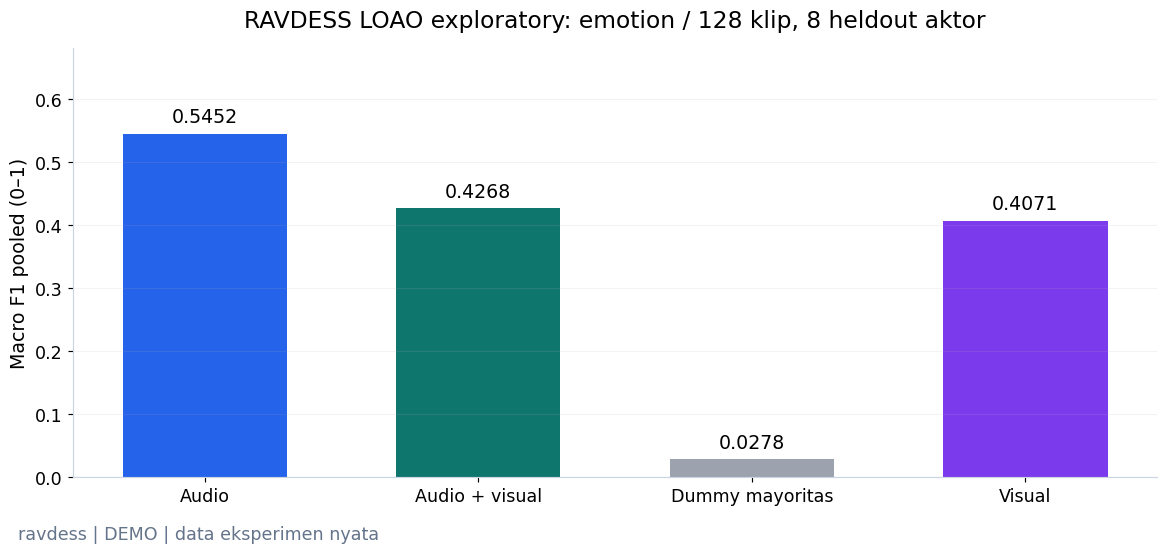

**Yang terlihat:** Empat model memakai delapan fold actor-independent yang identik; setiap klip diprediksi sekali ketika aktornya ditahan.

**Artinya:** Perbandingan ini menguji sensitivitas terhadap aktor tanpa memilih split dengan skor tertinggi.

**Perlu diingat:** Pooled F1 bukan rerata F1 per aktor; data sebelumnya sudah dipakai dalam pengembangan, sehingga bukti exploratory.

*Sumber: `20261023T105052302183Z_seed42_0d6280` · REAL / CACHED; inference dihitung ulang.*

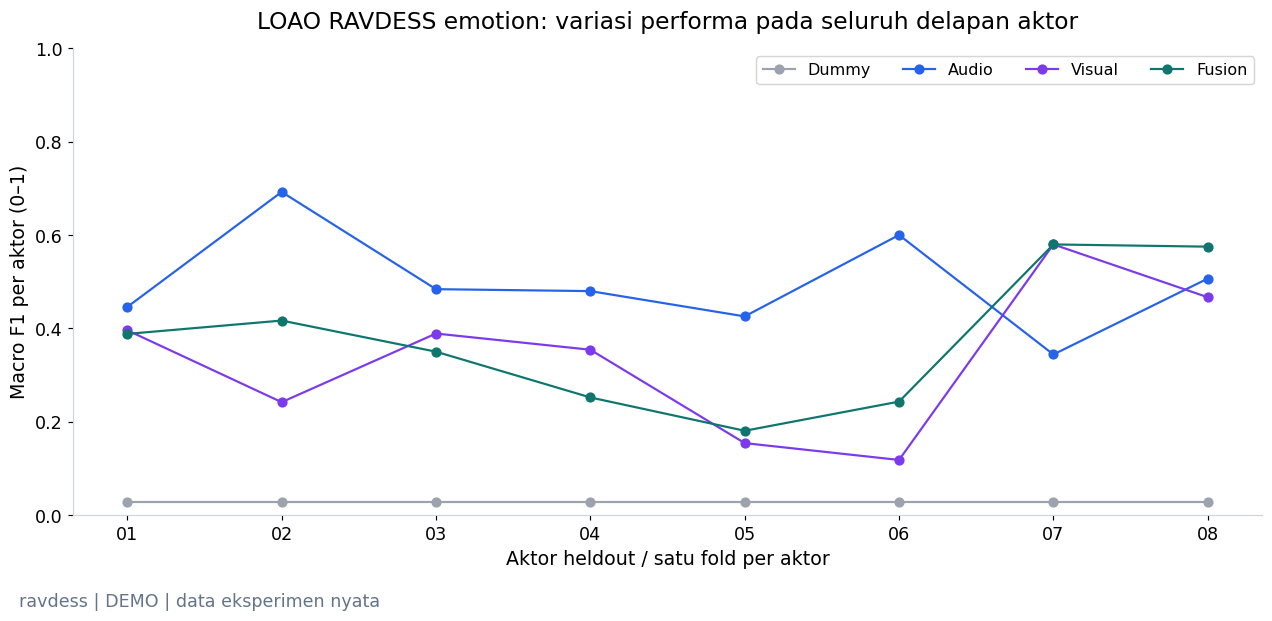

**Yang terlihat:** Setiap titik dihitung dari 16 recording aktor yang sama; garis menunjukkan variasi antaraktor, bukan urutan waktu.

**Artinya:** Keunggulan pooled dapat menyembunyikan aktor yang tidak terbantu fusion.

**Perlu diingat:** Hanya delapan aktor; simpangan baku/rentang bersifat deskriptif, bukan confidence interval atau bukti signifikansi.

*Sumber: `20261023T105052302183Z_seed42_0d6280` · REAL / CACHED; inference dihitung ulang.*

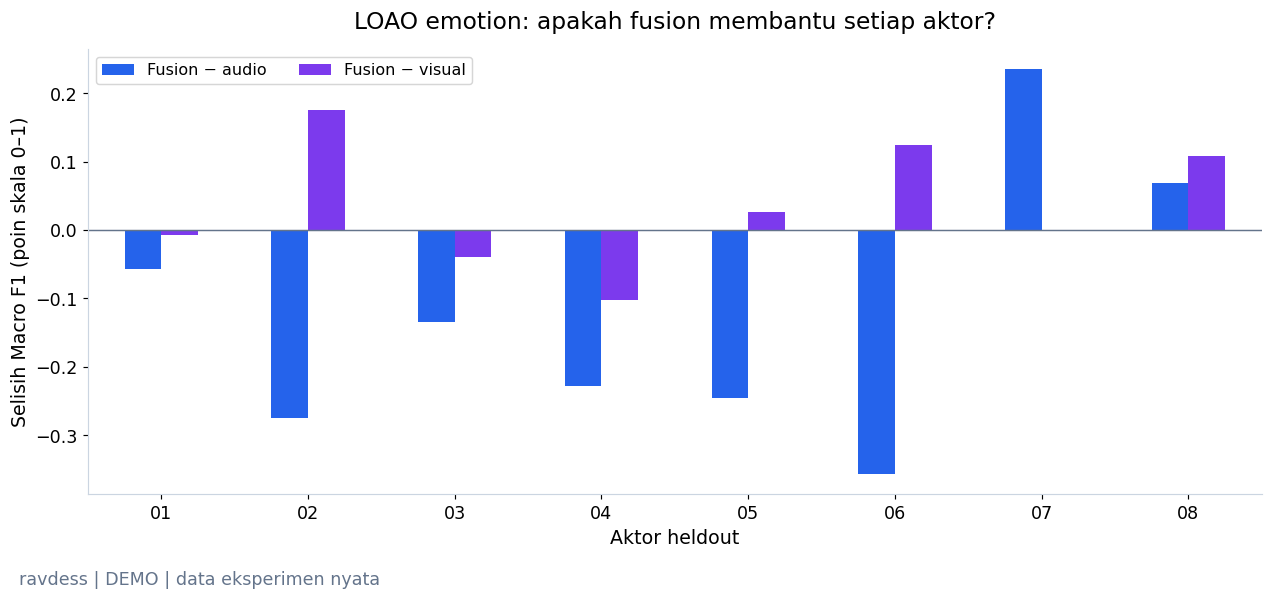

**Yang terlihat:** Fusion melampaui audio pada 2/8 aktor dan visual pada 4/8 aktor.

**Artinya:** Selisih dipasangkan pada aktor dan fold yang sama; nilai di bawah nol berarti fusion merugikan pada aktor itu.

**Perlu diingat:** Tidak ada bootstrap klip independen dan tidak ada klaim signifikansi dari delapan aktor.

*Sumber: `20261023T105052302183Z_seed42_0d6280` · REAL / CACHED; inference dihitung ulang.*

In [24]:
fig = model_bars(loao_pooled,'macro_f1','RAVDESS LOAO exploratory: emotion / 128 klip, 8 heldout aktor','Macro F1 pooled (0–1)',COLORS['fusion'])
loao_book.show(fig,'loao_model_comparison',
               'Empat model memakai delapan fold actor-independent yang identik; setiap klip diprediksi sekali ketika aktornya ditahan.',
               'Perbandingan ini menguji sensitivitas terhadap aktor tanpa memilih split dengan skor tertinggi.',
               'Pooled F1 bukan rerata F1 per aktor; data sebelumnya sudah dipakai dalam pengembangan, sehingga bukti exploratory.')
fig,ax = plt.subplots(figsize=(12,5.4),layout='constrained')
for name,label,color in [('dummy_majority','Dummy',COLORS['baseline']),('audio_only','Audio',COLORS['audio']),
                          ('visual_only','Visual',COLORS['visual']),('audio_visual','Fusion',COLORS['fusion'])]:
    subset = loao_actor_scores[loao_actor_scores.model.eq(name)].sort_values('subject_id')
    ax.plot(subset.subject_id,subset.macro_f1,marker='o',color=color,label=label,lw=1.5)
ax.set(xlabel='Aktor heldout / satu fold per aktor',ylabel='Macro F1 per aktor (0–1)',ylim=(0,1),
       title='LOAO RAVDESS emotion: variasi performa pada seluruh delapan aktor')
ax.legend(loc='upper right',ncol=4,fontsize=11)
loao_book.show(fig,'loao_actor_variation',
               'Setiap titik dihitung dari 16 recording aktor yang sama; garis menunjukkan variasi antaraktor, bukan urutan waktu.',
               'Keunggulan pooled dapat menyembunyikan aktor yang tidak terbantu fusion.',
               'Hanya delapan aktor; simpangan baku/rentang bersifat deskriptif, bukan confidence interval atau bukti signifikansi.')
actor_pivot = loao_actor_scores.pivot(index='subject_id',columns='model',values='macro_f1')
actor_deltas = pd.DataFrame({'Fusion − audio':actor_pivot.audio_visual-actor_pivot.audio_only,
                             'Fusion − visual':actor_pivot.audio_visual-actor_pivot.visual_only})
fig,ax = plt.subplots(figsize=(12,5.2),layout='constrained')
actor_deltas.plot.bar(ax=ax,rot=0,color=[COLORS['audio'],COLORS['visual']])
ax.axhline(0,color=COLORS['secondary'],lw=1)
ax.set(xlabel='Aktor heldout',ylabel='Selisih Macro F1 (poin skala 0–1)',title='LOAO emotion: apakah fusion membantu setiap aktor?')
ax.legend(loc='upper left',ncol=2,fontsize=11)
loao_book.show(fig,'loao_paired_actor_deltas',
               f'Fusion melampaui audio pada {int((actor_deltas.iloc[:,0]>0).sum())}/8 aktor dan visual pada {int((actor_deltas.iloc[:,1]>0).sum())}/8 aktor.',
               'Selisih dipasangkan pada aktor dan fold yang sama; nilai di bawah nol berarti fusion merugikan pada aktor itu.',
               'Tidak ada bootstrap klip independen dan tidak ada klaim signifikansi dari delapan aktor.')

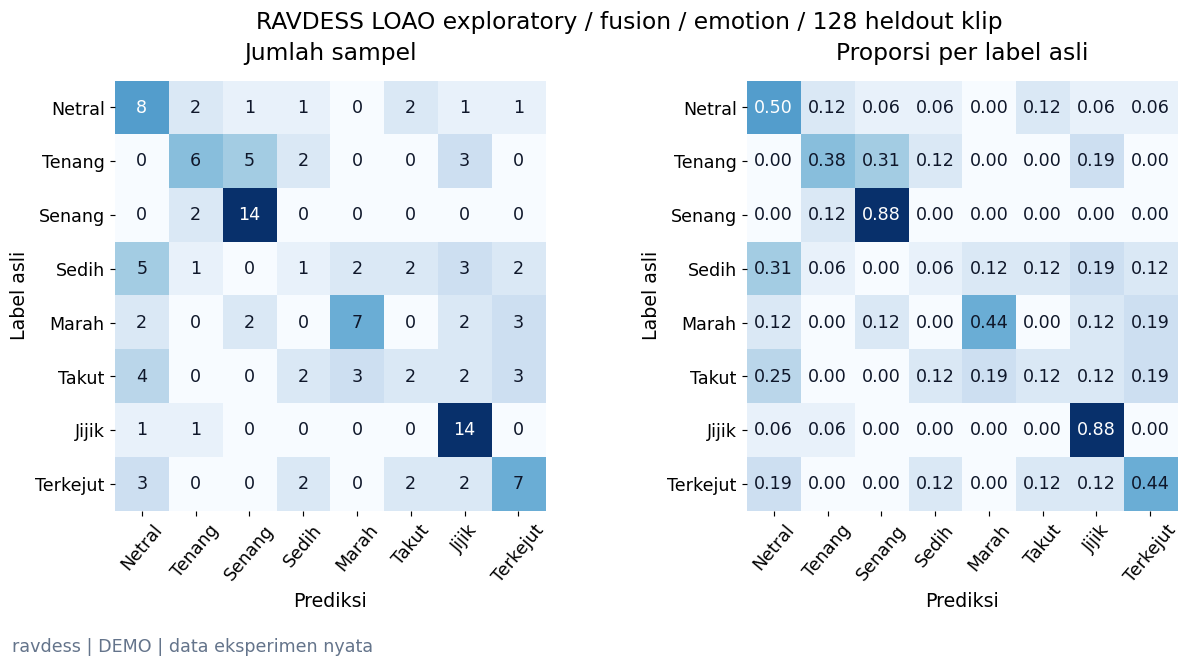

**Yang terlihat:** Setiap emotion memiliki 16 prediksi out-of-fold; matriks kiri absolut dan kanan ternormalisasi per label asli.

**Artinya:** Distribusi error menguji apakah hasil agregat menutupi kegagalan kelas tertentu.

**Perlu diingat:** Matriks menggabungkan delapan model/fold fusion yang dilatih berbeda; bukan satu checkpoint untuk semua data.

*Sumber: `20261023T105052302183Z_seed42_0d6280` · REAL / CACHED; inference dihitung ulang.*

,precision,recall,f1-score,support
Netral,0.348,0.500,0.410,16.0
Tenang,0.500,0.375,0.429,16.0
Senang,0.636,0.875,0.737,16.0
Sedih,0.125,0.062,0.083,16.0
Marah,0.583,0.438,0.500,16.0
Takut,0.250,0.125,0.167,16.0
Jijik,0.519,0.875,0.651,16.0
Terkejut,0.438,0.438,0.438,16.0


,Evaluasi,Fusion Macro F1,Test recording,Test aktor,Run
0,Historis dipertahankan,0.454899,32,2,20261022T081858104344Z_seed42_75d379
1,Reproduksi split historis,0.454899,32,2,20261023T104859625424Z_seed42_cce30b
2,LOAO exploratory,0.426792,128,8,20261023T105052302183Z_seed42_0d6280


**Apakah fusion lebih baik, dan seberapa kuat buktinya?** Pada split historis, Macro F1 fusion = 0.4549,
sementara audio = 0.3116 dan visual = 0.2797.
Dalam LOAO yang sebanding antar-model, pooled fusion = 0.4268, audio = 0.5452,
visual = 0.4071; F1 fusion per aktor berkisar 0.1806–0.5798.
**Jawaban:** fusion unggul pada split historis, tetapi LOAO tidak mendukung keunggulan fusion terhadap audio-only: audio-only lebih tinggi pada pooled F1. Keunggulan split lama tidak otomatis konsisten antaraktor. Lihat seluruh selisih per aktor dan kelas gagal sebelum menyimpulkan konsistensi. Bukti terbatas pada delapan aktor scripted emotion,
bukan konfirmasi generalisasi baru. Ukuran training dan populasi LOAO berbeda dari benchmark historis, sehingga selisih keduanya bukan efek metode.
Masking modalitas saat inference di bagian sebelumnya tidak melatih ketahanan terhadap modalitas hilang.
**Kemampuan mendeteksi fatigue operator ATC tetap belum diukur.**

In [25]:
loao_result = loao_pooled['audio_visual']
fig = confusion_pair(loao_result,list(EMOTIONS.values()),'RAVDESS LOAO exploratory / fusion / emotion / 128 heldout klip')
loao_book.show(fig,'loao_confusion',
               'Setiap emotion memiliki 16 prediksi out-of-fold; matriks kiri absolut dan kanan ternormalisasi per label asli.',
               'Distribusi error menguji apakah hasil agregat menutupi kegagalan kelas tertentu.',
               'Matriks menggabungkan delapan model/fold fusion yang dilatih berbeda; bukan satu checkpoint untuk semua data.')
display(pd.DataFrame({label:loao_result['classification_report'][str(value)] for value,label in EMOTIONS.items()}).T[
    ['precision','recall','f1-score','support']].round(3))
loao_book.finish()
if RUN_MODE == 'FULL':
    loao_run.complete(loao_metrics,{'evaluation_rows':len(loao_data),'subjects':8,'folds':8,'subject_overlap':0,
                                   'models_reloaded':32,'parent_features_verified':True},warning_records)
historical_run,historical_metrics = cached_run('ravdess_emotion',config,run_id=config['historical_runs']['ravdess_emotion'])
historical_f1 = historical_metrics['models']['audio_visual']['test']['macro_f1']
np.testing.assert_allclose(fusion_result['macro_f1'],historical_f1,rtol=1e-12,atol=1e-12)
display(pd.DataFrame([
    {'Evaluasi':'Historis dipertahankan','Fusion Macro F1':historical_f1,'Test recording':32,'Test aktor':2,'Run':historical_run.manifest['run_id']},
    {'Evaluasi':'Reproduksi split historis','Fusion Macro F1':fusion_result['macro_f1'],'Test recording':32,'Test aktor':2,'Run':fusion_run.manifest['run_id']},
    {'Evaluasi':'LOAO exploratory','Fusion Macro F1':loao_result['macro_f1'],'Test recording':128,'Test aktor':8,'Run':loao_run.manifest['run_id']}]))
display(Markdown(f"""**Apakah fusion lebih baik, dan seberapa kuat buktinya?** Pada split historis, Macro F1 fusion = {fusion_result['macro_f1']:.4f},
sementara audio = {fusion_test_scores['audio_only']['macro_f1']:.4f} dan visual = {fusion_test_scores['visual_only']['macro_f1']:.4f}.
Dalam LOAO yang sebanding antar-model, pooled fusion = {loao_result['macro_f1']:.4f}, audio = {loao_pooled['audio_only']['macro_f1']:.4f},
visual = {loao_pooled['visual_only']['macro_f1']:.4f}; F1 fusion per aktor berkisar {loao_variation.loc['audio_visual','min']:.4f}–{loao_variation.loc['audio_visual','max']:.4f}.
**Jawaban:** fusion unggul pada split historis, tetapi LOAO tidak mendukung keunggulan fusion terhadap audio-only: {('audio-only lebih tinggi' if loao_pooled['audio_only']['macro_f1']>loao_result['macro_f1'] else 'fusion lebih tinggi')} pada pooled F1. Keunggulan split lama tidak otomatis konsisten antaraktor. Lihat seluruh selisih per aktor dan kelas gagal sebelum menyimpulkan konsistensi. Bukti terbatas pada delapan aktor scripted emotion,
bukan konfirmasi generalisasi baru. Ukuran training dan populasi LOAO berbeda dari benchmark historis, sehingga selisih keduanya bukan efek metode.
Masking modalitas saat inference di bagian sebelumnya tidak melatih ketahanan terhadap modalitas hilang.
**Kemampuan mendeteksi fatigue operator ATC tetap belum diukur.**"""))

<a id="6-sintesis-kesiapan-penelitian"></a>

## 6. Sintesis kesiapan penelitian

> **Akurasi deteksi fatigue ATC multimodal: BELUM DIUKUR.**  
> **Performa multimodal fatigue ATC belum diukur.**

Empat sumber bukti menjawab pertanyaan yang berbeda. Scorecards berikut mempertahankan nama target, metrik, penyebut, dan sumber run. Tidak ada satu leaderboard yang mencampur Macro F1 dan MAE.

Bagian sintesis dapat menampilkan run audio/visual yang sudah selesai, tetapi eksperimen RAVDESS di atas tidak bergantung pada variabel notebook lain. Jika artefak sintesis belum tersedia, statusnya ditandai belum tersedia tanpa angka pengganti.

In [26]:
synthesis_rows = []
for slug,label,model,metric in [('atcosim_audio','ATCOSIM / ekstraksi',None,None),
                               ('mrl_eye_state','MRL / eye state','hog_linear_svm','macro_f1'),
                               ('drozy_kss','DROZY / KSS sleepiness','ridge_alpha1','mae')]:
    try:
        source_run,source_metrics = cached_run(slug,config)
    except FileNotFoundError:
        synthesis_rows.append({'Bukti':label,'Status':'Belum tersedia lokal','Hasil':'N/A','Sumber run':'N/A'})
        continue
    value = source_metrics['models'][model] if model else None
    if value is not None and metric=='macro_f1': value=value['test']
    result = '114 fitur; tidak ada skor supervised' if value is None else f'{metric} = {value[metric]:.4f}'
    if metric=='macro_f1':
        split = pd.read_csv(source_run.path / 'split_manifest.csv',dtype={'subject_id':str})
        denominator = f"{source_metrics['n_test']} gambar / {split[split.split.eq('test')].subject_id.nunique()} subjek test"
    elif metric=='mae':
        denominator = f"{source_metrics['n_test']} original tests / {source_metrics['n_subjects']} subjek LOSO"
    else:
        denominator = f"{source_run.manifest['n_samples']} ujaran / {source_run.manifest['n_subjects']} speaker"
    synthesis_rows.append({'Bukti':label,'Status':'CACHED FULL terverifikasi','Hasil':result,'Unit / penyebut':denominator,'Sumber run':source_run.manifest['run_id']})
synthesis_rows.append({'Bukti':'RAVDESS / emotion','Status':'FRESH FULL' if RUN_MODE=='FULL' else 'CACHED FULL + inference FRESH',
                        'Hasil':f"Macro F1 = {fusion_result['macro_f1']:.4f}",'Unit / penyebut':f'{len(fusion_test)} klip / 2 aktor test','Sumber run':fusion_run.manifest['run_id']})
display(pd.DataFrame(synthesis_rows))

,Bukti,Status,Hasil,Unit / penyebut,Sumber run
0,ATCOSIM / ekstraksi,CACHED FULL terverifikasi,114 fitur; tidak ada skor supervised,100 ujaran / 1 speaker,20261023T105347534495Z_seed42_49cb09
1,MRL / eye state,CACHED FULL terverifikasi,macro_f1 = 0.7877,1159 gambar / 8 subjek test,20261023T110123270660Z_seed42_29f903
2,DROZY / KSS sleepiness,CACHED FULL terverifikasi,mae = 1.4544,36 original tests / 14 subjek LOSO,20261023T110137480062Z_seed42_566711
3,RAVDESS / emotion,CACHED FULL + inference FRESH,Macro F1 = 0.4549,32 klip / 2 aktor test,20261023T104859625424Z_seed42_cce30b


### Peta kesiapan berbasis bukti

| Komponen | Bukti sekarang | Syarat penelitian ATC berikutnya |
| :--- | :--- | :--- |
| Audio | WAV → 114 fitur + QC | Audio fatigue berlabel dan variasi operator/perangkat |
| Visual | Eye-state model; EAR/window; KSS offline | Kalibrasi closure/blink, kualitas NIR/RGB, waktu label |
| Pairing | AV dari recording RAVDESS yang sama | Audio-video ATC sinkron dari operator/sesi yang sama |
| Modeling | Dummy dan baseline unimodal/static fusion | Ground truth fatigue yang sah, split operator, data temporal cukup |
| Reproduksi | Run unik, config, environment, checkpoints, reload | Protokol preregistered dan validasi eksternal |
| Temporal | Guard urutan tersedia pada package lama | GRU/TCN belum dilatih; perlu baseline dan data berurutan yang valid |

### Ringkasan 90 detik untuk Prof

Kita sudah membuktikan proses input → representasi numerik → model → evaluasi yang dapat diulang. Audio ATC menghasilkan fitur, gambar mata menghasilkan model open/closed, pola mata dipakai untuk regresi sleepiness, dan pasangan AV asli dipakai untuk emotion fusion. Setiap skor punya target dan batasnya sendiri.

Tahap berikutnya memerlukan protokol fatigue bersama Prof, izin rekaman, pasangan audio-video ATC yang sinkron, dan label fatigue independen. Permintaan IEEE sudah dikirim pengguna menurut spesifikasi v3; aksesnya belum tersedia dan korpus itu pun hanya kandidat **audio** fatigue. Kita belum melatih GRU/TCN, belum memvalidasi peringatan real-time, dan belum memiliki skor fatigue ATC multimodal.

## 7. Provenance dan reproduksi

Semua model memakai split aktor yang sudah dibekukan; preprocessing di-fit hanya pada training. FULL menyimpan seluruh artefak ke run baru; DEMO memverifikasi cache/checkpoint lalu menjalankan contoh asli secara langsung. Data mentah, fitur lengkap, model, prediksi per recording, dan executed FULL notebooks tetap lokal.

In [27]:
fusion_book.finish()
if RUN_MODE=='FULL':
    fusion_run.complete(fusion_metrics,{'evaluation_rows':len(fusion_data),'subjects':int(fusion_data.subject_id.nunique()),
                                       'pairing':'same original AV container; source checksums verified',
                                       'subject_overlap':0,'feature_missing_fraction':float(fusion_data[fusion_columns].isna().mean().mean()),
                                       'audio_available':float(fusion_data.audio_available.mean()),
                                       'video_available':float(fusion_data.video_available.mean())},warning_records)
display(pd.DataFrame([{'Run ID':fusion_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Target':'emotion','Klip':len(fusion_data),'Aktor':fusion_data.subject_id.nunique(),
                       'Model reload':'Diverifikasi pada holdout','Artifact':str(fusion_run.path.relative_to(ROOT)),
                       'Fatigue ATC multimodal':'BELUM DIUKUR'}]))
warning_context.__exit__(None,None,None)

,Run ID,Mode,Target,Klip,Aktor,Model reload,Artifact,Fatigue ATC multimodal
0,20261023T104859625424Z_seed42_cce30b,DEMO,emotion,128,8,Diverifikasi pada holdout,runs/ravdess_emotion/20261023T104859625424Z_se...,BELUM DIUKUR


Untuk presentasi, gunakan mode default DEMO dan ikuti rute di awal. Untuk mengulang feature extraction/training, gunakan `--mode FULL` pada [runner v3](../../scripts/10_execute_notebook_v3.py). Run baru tidak menggantikan hasil lama. [Panduan lengkap](README.md).

---
## A. Late Fusion — Decision-Level Audio/Visual Integration

**Pertanyaan:** jika audio dan video diproses oleh model terpisah, apakah menggabungkan probabilitasnya membantu pada aktor yang belum dilihat?

Bagian ini merupakan tambahan penelitian, bukan penggantian hasil di atas. **REAL / CACHED** berarti hasil training nyata yang sudah disimpan dan diperiksa. **FRESH replay** berarti inference checkpoint yang dihitung lagi, tanpa melatih model baru. Semua grafik hasil di sini memakai **128 genuine paired RAVDESS recordings, 8 aktor, 8 emotion**. Tidak ada label fatigue ATC.

Urutannya: fitur nyata → pipeline train-only → prediksi per cabang → probabilitas gabungan → evaluasi per recording → interpretasi antaraktor. Tidak ada audio atau citra wajah baru ditanam ke output ini.


In [1]:
from pathlib import Path
import hashlib
import json
import re
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
def load_extension(name):
    return json.loads((PROJECT_ROOT / 'reports' / name).read_text())

extension = load_extension('fusion_extension_results.json')
extension_figures = load_extension('fusion_extension_figures.json')
assert extension['status'] == 'COMPLETED — RAVDESS EXPERIMENT'
assert extension['checks']['prediction_rows'] == 6144
print('CACHED: real RAVDESS training; eight actor-independent folds; primary seed42.')


CACHED: real RAVDESS training; eight actor-independent folds; primary seed42.


In [2]:
def show_extension_figure(name):
    entry = extension_figures[name]
    path = PROJECT_ROOT / entry['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == entry['sha256']
    display(Image(filename=str(path)))

folds_extension = pd.read_csv(PROJECT_ROOT / 'reports/fusion_extension_folds.csv', dtype={'subject_id': str})
display(folds_extension.groupby(['fold', 'split']).agg(recordings=('sample_id', 'size'), actors=('subject_id', 'nunique')))


recordings  actors
fold split                         
1    test                16       1
     train               80       5
     validation          32       2
2    test                16       1
     train               80       5
     validation          32       2
3    test                16       1
     train               80       5
     validation          32       2
4    test                16       1
     train               80       5
     validation          32       2
5    test                16       1
     train               80       5
     validation          32       2
6    test                16       1
     train               80       5
     validation          32       2
7    test                16       1
     train               80       5
     validation          32       2
8    test                16       1
     train               80       5
     validation          32       2

### Data, provenance, dan evaluasi yang sebanding

Satu row adalah satu rekaman audio-video asli; audio dan video memiliki source checksum yang sama karena berasal dari file AV yang sama. Label asli RAVDESS adalah emotion 1–8, masing-masing 16 rekaman. Semua recording dari satu aktor tetap dalam partisi yang sama.

Protokol baru memakai **5 aktor train /2 validation /1 test** pada setiap outer Leave-One-Actor-Out(LOAO) fold. Dua aktor validation adalah dua aktor berikutnya secara siklik, ditentukan sebelum skor model. Validation hanya memilih bobot late fusion atau checkpoint CNN; tidak dimasukkan kembali ke training.

Hasil historis di atas memakai protokol berbeda: LOAO lama 7 train/1 test, tanpa inner validation. Oleh karena itu semua baseline dihitung ulang pada protokol baru. Skor lama tetap valid sebagai sejarah, tetapi **tidak dibandingkan seolah ukuran training sama**. Semua 8 aktor pernah dipakai pengembangan, sehingga analisis ini exploratory.


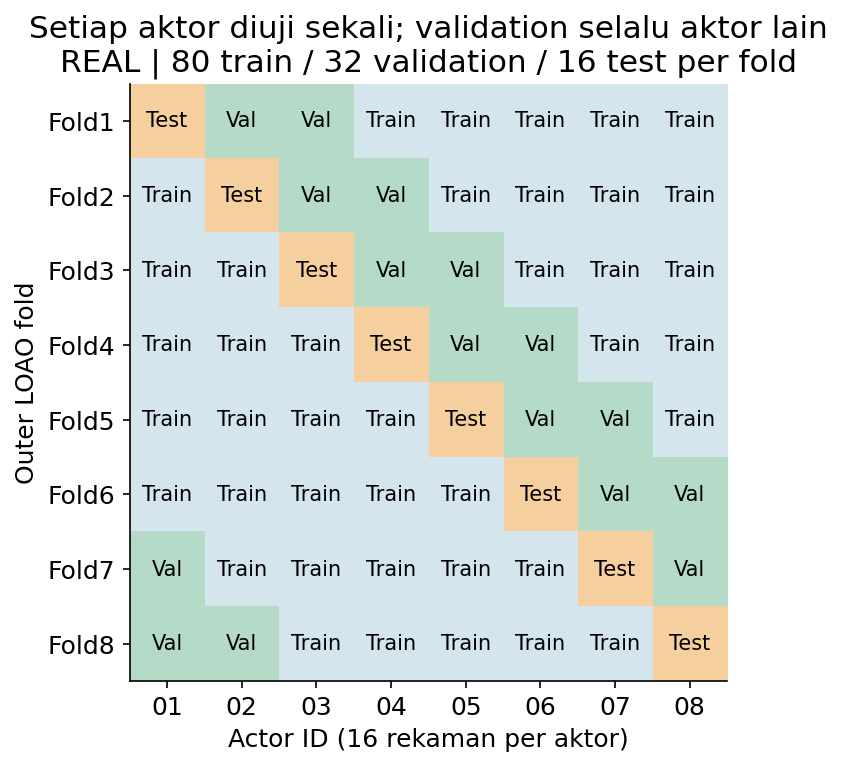

In [3]:
show_extension_figure('folds')

**Yang terlihat:** Setiap aktor menjadi test tepat sekali. Dalam satu fold tidak ada actor atau recording overlap.

**Artinya:** Model dibandingkan pada 80 train, 32 validation, 16 test recording yang persis sama.

**Perlu diingat:** Hanya 8 aktor; banyak outer training fold saling tumpang tindih. Ini belum validasi populasi ATC.

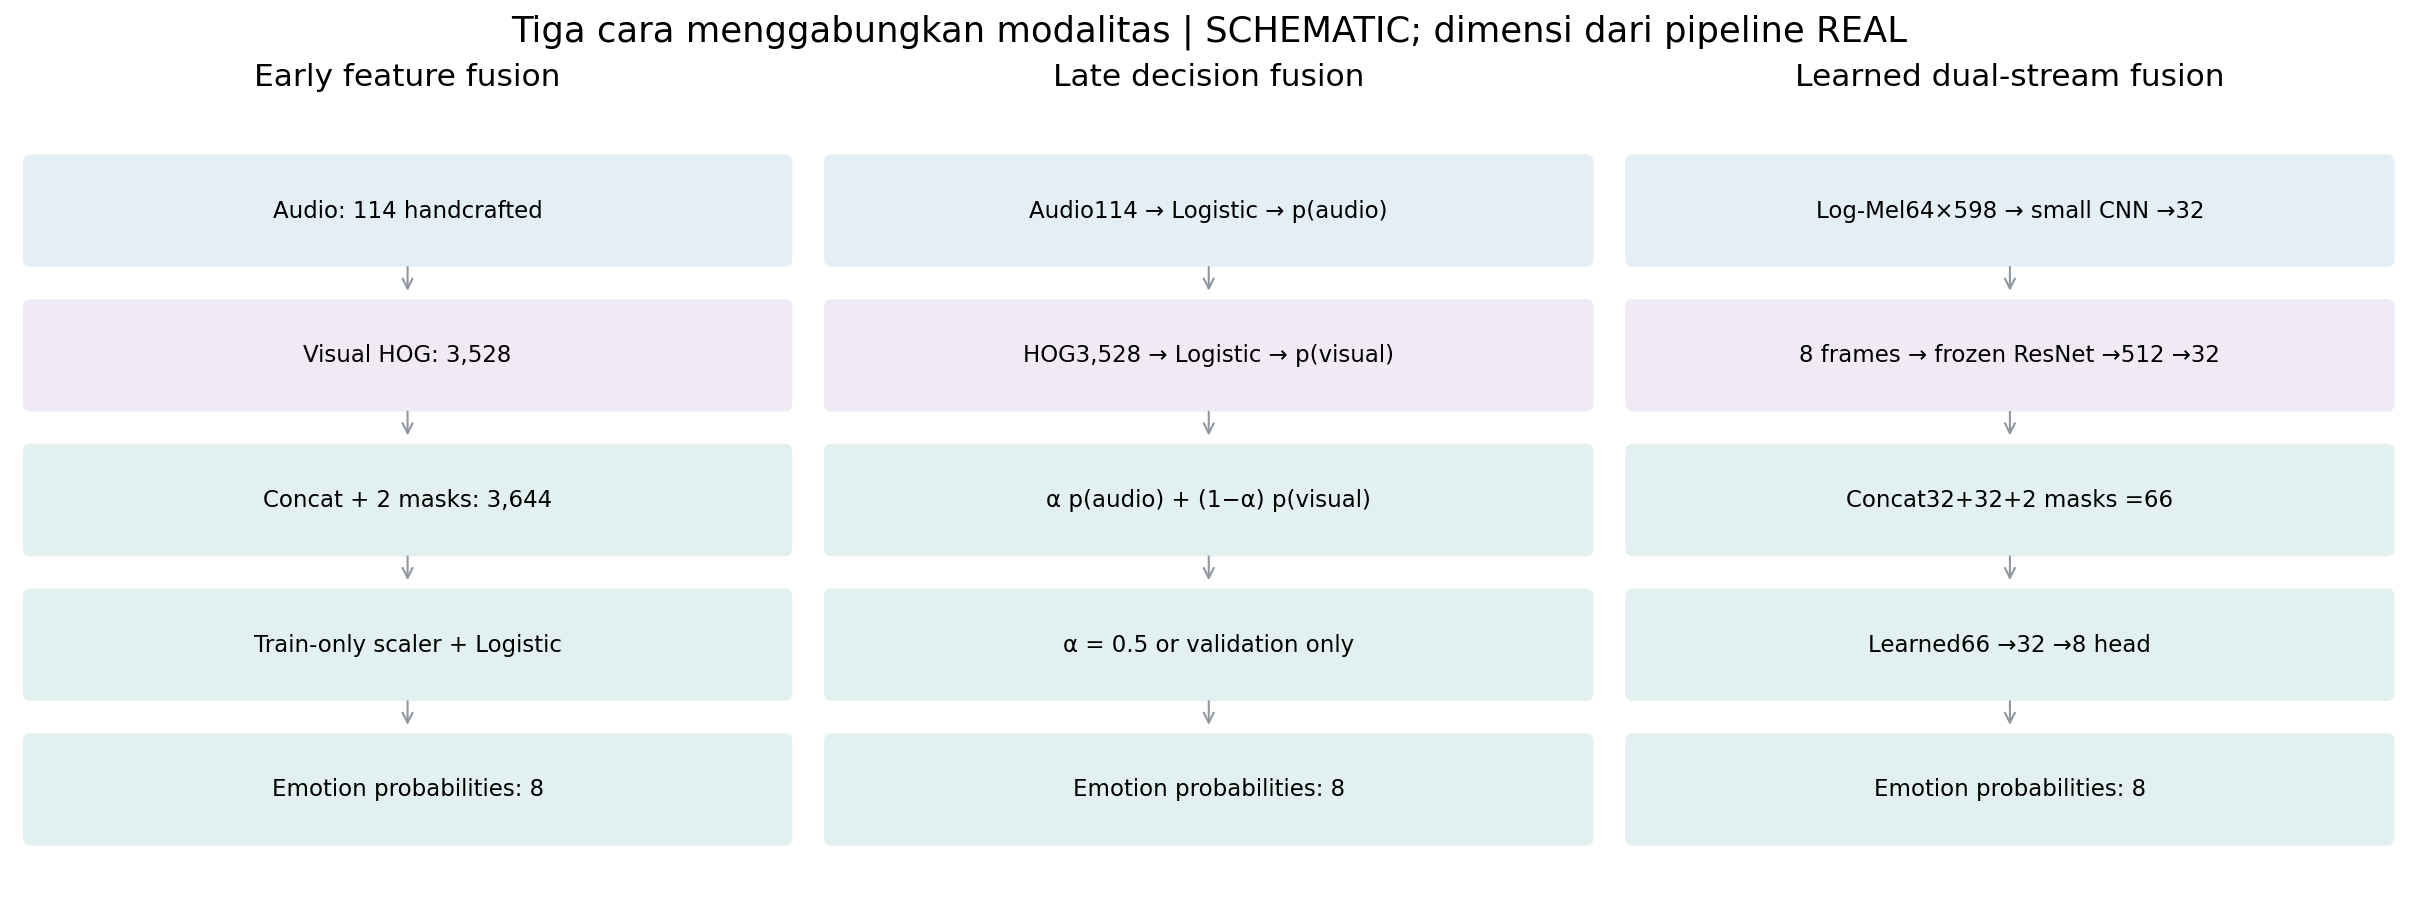

In [4]:
show_extension_figure('architectures')

**Yang terlihat:** Early memakai 3.644 fitur, late menggabungkan dua vektor probabilitas 8 kelas, dan dual-stream memakai 66 komponen sebelum head.

**Artinya:** Feature-level fusion menggabungkan representasi sebelum keputusan; decision-level fusion menggabungkan keputusan cabang.

**Perlu diingat:** Diagram adalah SCHEMATIC dengan dimensi dari pipeline nyata; gambar bukan hasil observasi fisiologis.

### Angka input model: contoh nyata, bukan fixture

Audio menggunakan 88 eGeMAPSv02 functionals+26 MFCC mean/std=114 fitur. HOG visual adalah appearance descriptor, bukan EAR/PERCLOS. Model classical memakai median imputation dan StandardScaler yang di-fit hanya pada 80 recording train fold masing-masing. Target, actor ID, filename, dan timestamp tidak dipakai sebagai predictor.

Tabel berikut menunjukkan 3 baris train sebenarnya dari fold 01, dengan 8 kolom contoh dari 114 fitur audio. Nilai raw dan scaled berasal dari row dan model train yang sama; ringkasan ini tidak menggantikan schema lengkap lokal. Angka setelah scaling memakai satuan standard-deviation train, sehingga besarannya tidak boleh ditafsirkan sebagai satuan akustik asli.


In [5]:
preview_extension = load_extension('fusion_extension_feature_preview.json')
print('X audio:', preview_extension['audio_matrix_shapes'])
print('Feature dimensions:', preview_extension['dimensions'])
print('Missing audio feature values in fold01 train:', preview_extension['missing_raw_audio_values_train'])
raw_preview = pd.DataFrame(preview_extension['raw_first3_rows'], columns=preview_extension['feature_names_shown'], index=preview_extension['sample_ids'])
scaled_preview = pd.DataFrame(preview_extension['scaled_first3_rows'], columns=preview_extension['feature_names_shown'], index=preview_extension['sample_ids'])
display(Markdown('**REAL / CACHED: raw features → train-only scaled features**'))
display(raw_preview.round(4))
display(scaled_preview.round(4))
print('y_train first3 native emotion labels:', preview_extension['target_first3'])


X audio: {'train': [80, 114], 'validation': [32, 114], 'test': [16, 114]}
Feature dimensions: {'dummy_majority': 114, 'audio_logistic': 114, 'visual_logistic': 3528, 'early_fusion': 3644}
Missing audio feature values in fold01 train: 0


**REAL / CACHED: raw features → train-only scaled features**

,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,mfcc_09_std,mfcc_10_std,mfcc_11_std,mfcc_12_std
01-01-01-01-01-01-04,37.6040,0.1242,32.5384,37.6148,6.5932,9.9959,6.5084,5.8299
01-01-01-01-01-01-05,26.2497,0.0948,24.3588,27.2301,11.4327,9.7721,6.5975,9.6048
01-01-01-01-01-01-06,37.3183,0.0711,34.9319,36.8344,10.9213,9.9405,12.2050,9.6015


,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,mfcc_09_std,mfcc_10_std,mfcc_11_std,mfcc_12_std
01-01-01-01-01-01-04,0.6454,1.1362,0.2067,0.6750,-2.1604,-0.4456,-1.1694,-1.6893
01-01-01-01-01-01-05,-1.3172,0.2545,-1.2484,-1.1031,0.4900,-0.5611,-1.1286,0.1721
01-01-01-01-01-01-06,0.5960,-0.4575,0.6325,0.5414,0.2099,-0.4742,1.4388,0.1705


y_train first3 native emotion labels: [1, 1, 1]


### Dua aturan late fusion yang ditetapkan sebelum test

**L 1—equal:** `p =0.5*p_audio+0.5*p_visual`. Setiap cabang adalah Logistic Regression terpisah(C 1, balanced) pada fitur train-only-scaled. Kelas probabilitas diselaraskan menurut label 1–8. Ini native multinomial softmax yang dinormalisasi, **bukan klaim probabilitas terkalibrasi eksternal**.

**L 2—weighted:** bobot audio dipilih dari`[0,0.25,0.5,0.75,1]` menggunakan rerata Macro F1 dua aktor validation. Jika seri, pilih yang paling dekat 0,5, lalu yang lebih kecil. Test actor tidak dilihat untuk memilih bobot. Dua aktor validation merupakan sampel kecil, sehingga bobot yang cocok pada validation bisa gagal pada test.


In [6]:
weight_rows = [{'fold': row['fold'], 'audio_weight': row['selected_audio_weight'], 'visual_weight': 1-row['selected_audio_weight']} for row in extension['selected_weights']]
display(pd.DataFrame(weight_rows))
metric_rows = []
for model in ['dummy_majority','audio_logistic','visual_logistic','early_fusion','late_equal','late_weighted']:
    score = extension['metrics'][f'{model}/seed42/complete']
    metric_rows.append({'model': model, **{key: score[key] for key in ['macro_f1','balanced_accuracy','accuracy','actor_macro_f1']}})
display(pd.DataFrame(metric_rows).round(4))


,fold,audio_weight,visual_weight
0,1,1.00,0.00
1,2,0.75,0.25
2,3,0.50,0.50
3,4,0.50,0.50
4,5,0.50,0.50
5,6,0.25,0.75
6,7,0.50,0.50
7,8,0.50,0.50


,model,macro_f1,balanced_accuracy,accuracy,actor_macro_f1
0,dummy_majority,0.0278,0.1250,0.1250,0.0278
1,audio_logistic,0.4952,0.5078,0.5078,0.4503
2,visual_logistic,0.3658,0.3906,0.3906,0.3031
3,early_fusion,0.3949,0.4219,0.4219,0.3478
4,late_equal,0.5071,0.5156,0.5156,0.4571
5,late_weighted,0.4721,0.4844,0.4844,0.4190


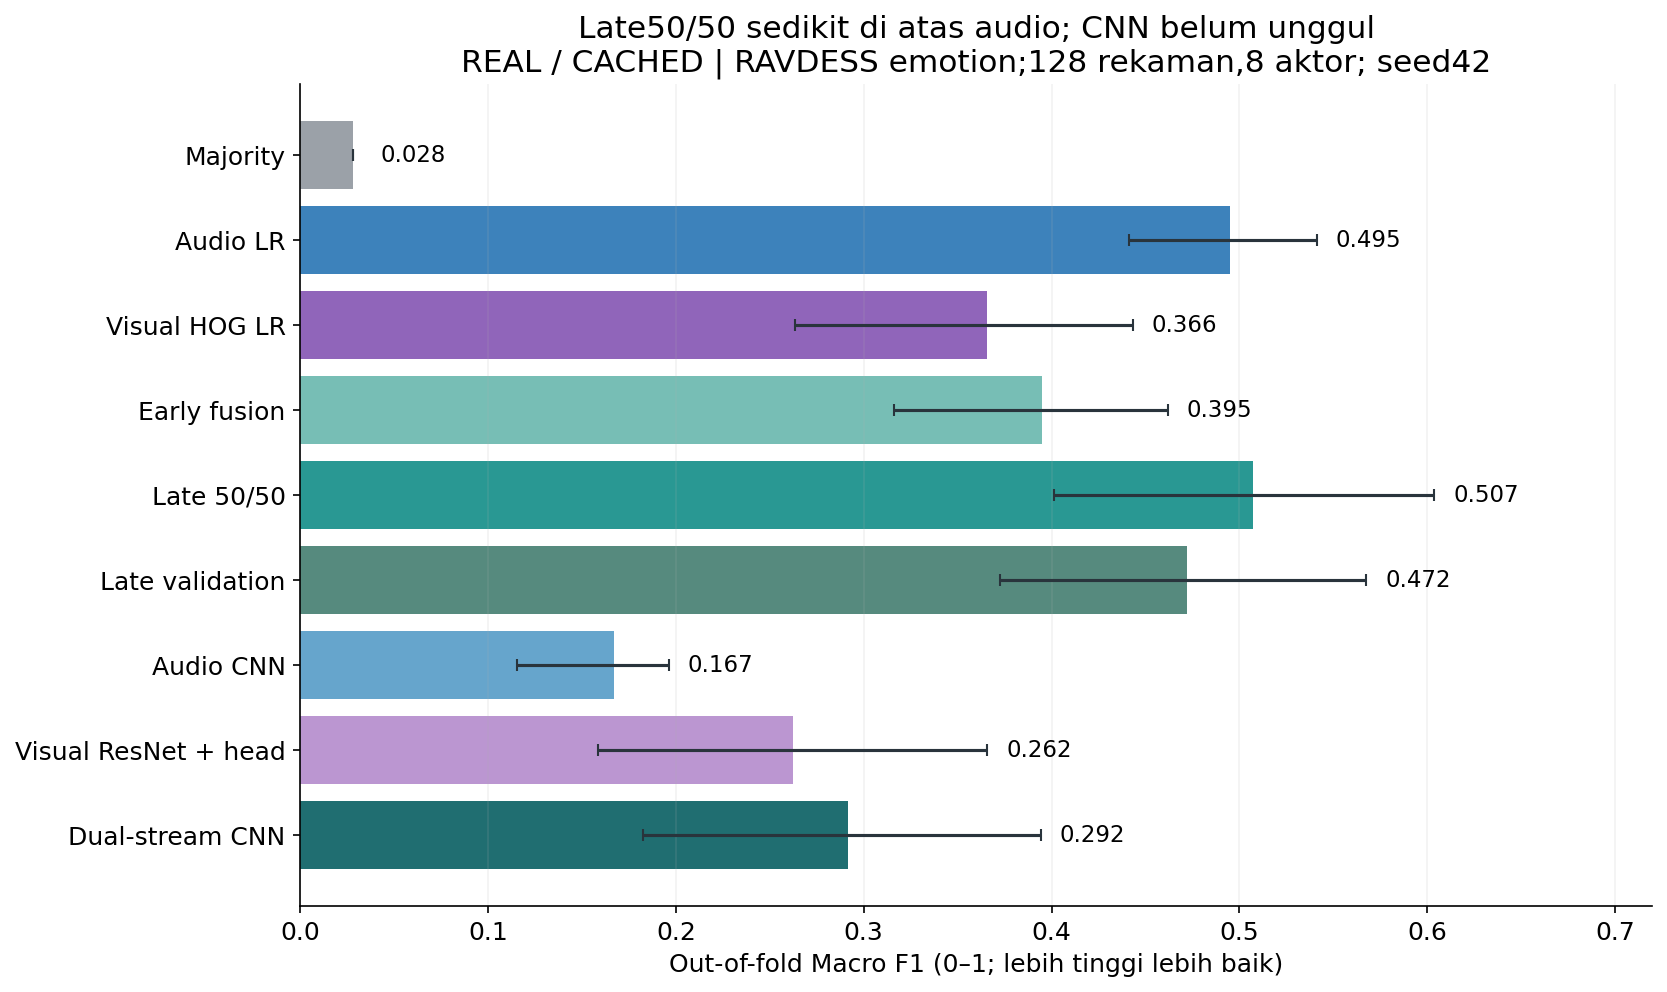

In [7]:
show_extension_figure('comparison')

**Yang terlihat:** Late 50/50 Macro F1=0.5071, audio LR=0.4952, early=0.3949; dual-stream=0.2916.

**Artinya:** Menggabungkan probabilitas sedikit membantu pooled score pada protokol ini; model lebih kompleks belum lebih baik.

**Perlu diingat:** Interval paired selisih late 50/50−audio=[−0.1056,+0.1257]. Errorbar actor-bootstrap bersifat deskriptif dari OOF tetap, bukan bukti signifikansi atau retraining uncertainty.

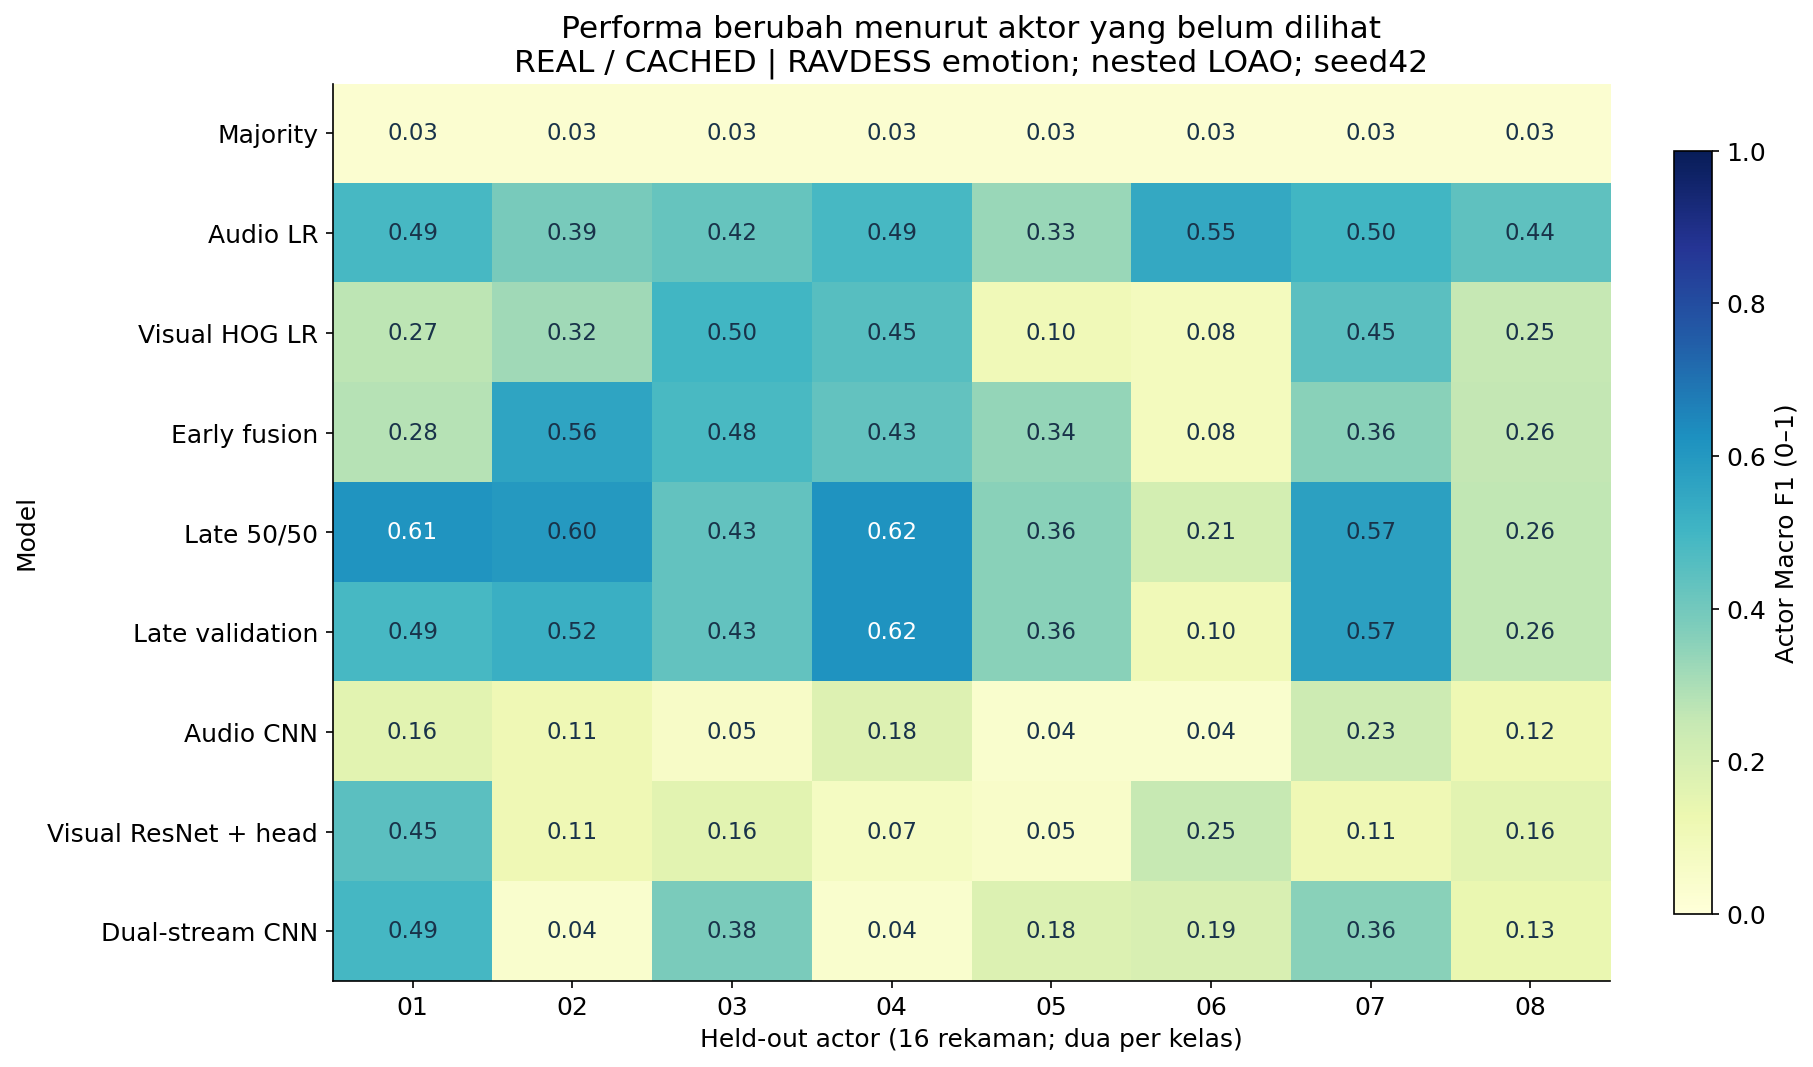

In [8]:
show_extension_figure('actor_performance')

**Yang terlihat:** Late 50/50 lebih baik dari audio pada 6/8 aktor, tetapi turun besar padaaktor 06 dan 08. Late weighted menang 5, seri 1, kalah 2.

**Artinya:** Skor pooled kecil dapat menyembunyikan ketergantungan pada aktor. Bobot dari validation tidak menjamin generalisasi.

**Perlu diingat:** Setiap test actor hanya 16 recording dan 2 perkelas; actor-Macro F1 rata-rata berbeda dari pooled OOF Macro F1.

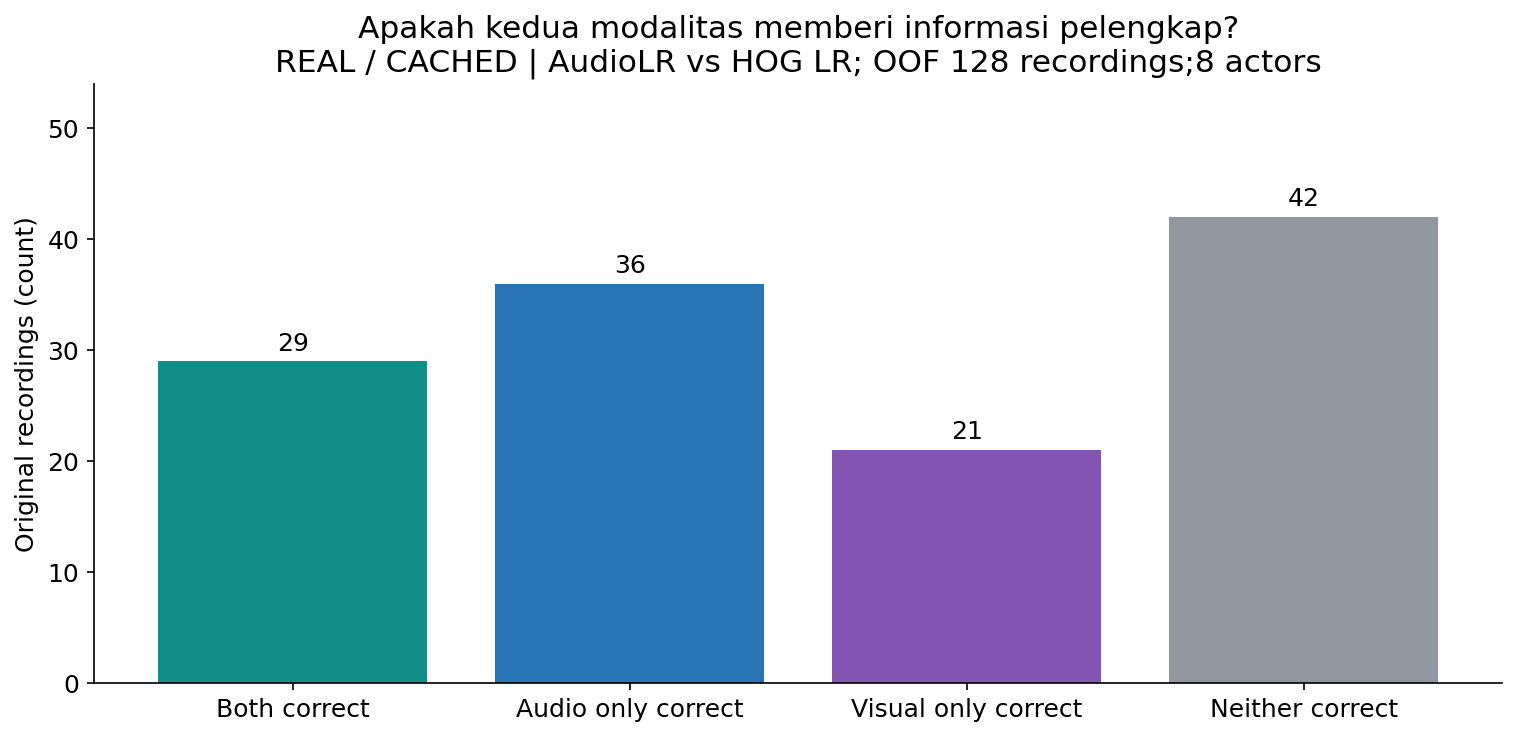

In [9]:
show_extension_figure('complementarity')

**Yang terlihat:** Audio saja benar 36 kasus, visual saja 21, keduanya benar 29, keduanya salah 42;93 prediksi cabang berbeda.

**Artinya:** Visual kadang memiliki informasi yang tidak tertangkap audio, namun fusion harus memutuskan tanpa melihat ground truth.

**Perlu diingat:** Oracle ‘salah satu benar’86/128 bukan accuracy sistem yang dapat dipakai; tidak ada cherry-picking model per recording.

### Missing modality: keputusan saat sensor tidak tersedia

Late fusion memberi bobot nol pada cabang yang hilang lalu menormalisasi bobot cabang yang tersedia. Bobot endpoint 0/1 tetap bisa fallback ke satu sensor yang tersisa. Jika keduanya hilang, gunakan prior kelas dari train dan status unavailable; itu tidak berarti sistem mengamati sinyal normal.

Early fusion hanya diuji dengan NaN→median train dan availability maskFalse; masker inference tidak sama dengan training robust sensor hilang. Dual-stream mendapat modality dropout train-only yang dijelaskan di bagianB. Skenario missing dibuat dari recording yang sama, **bukan observasi independen tambahan**.


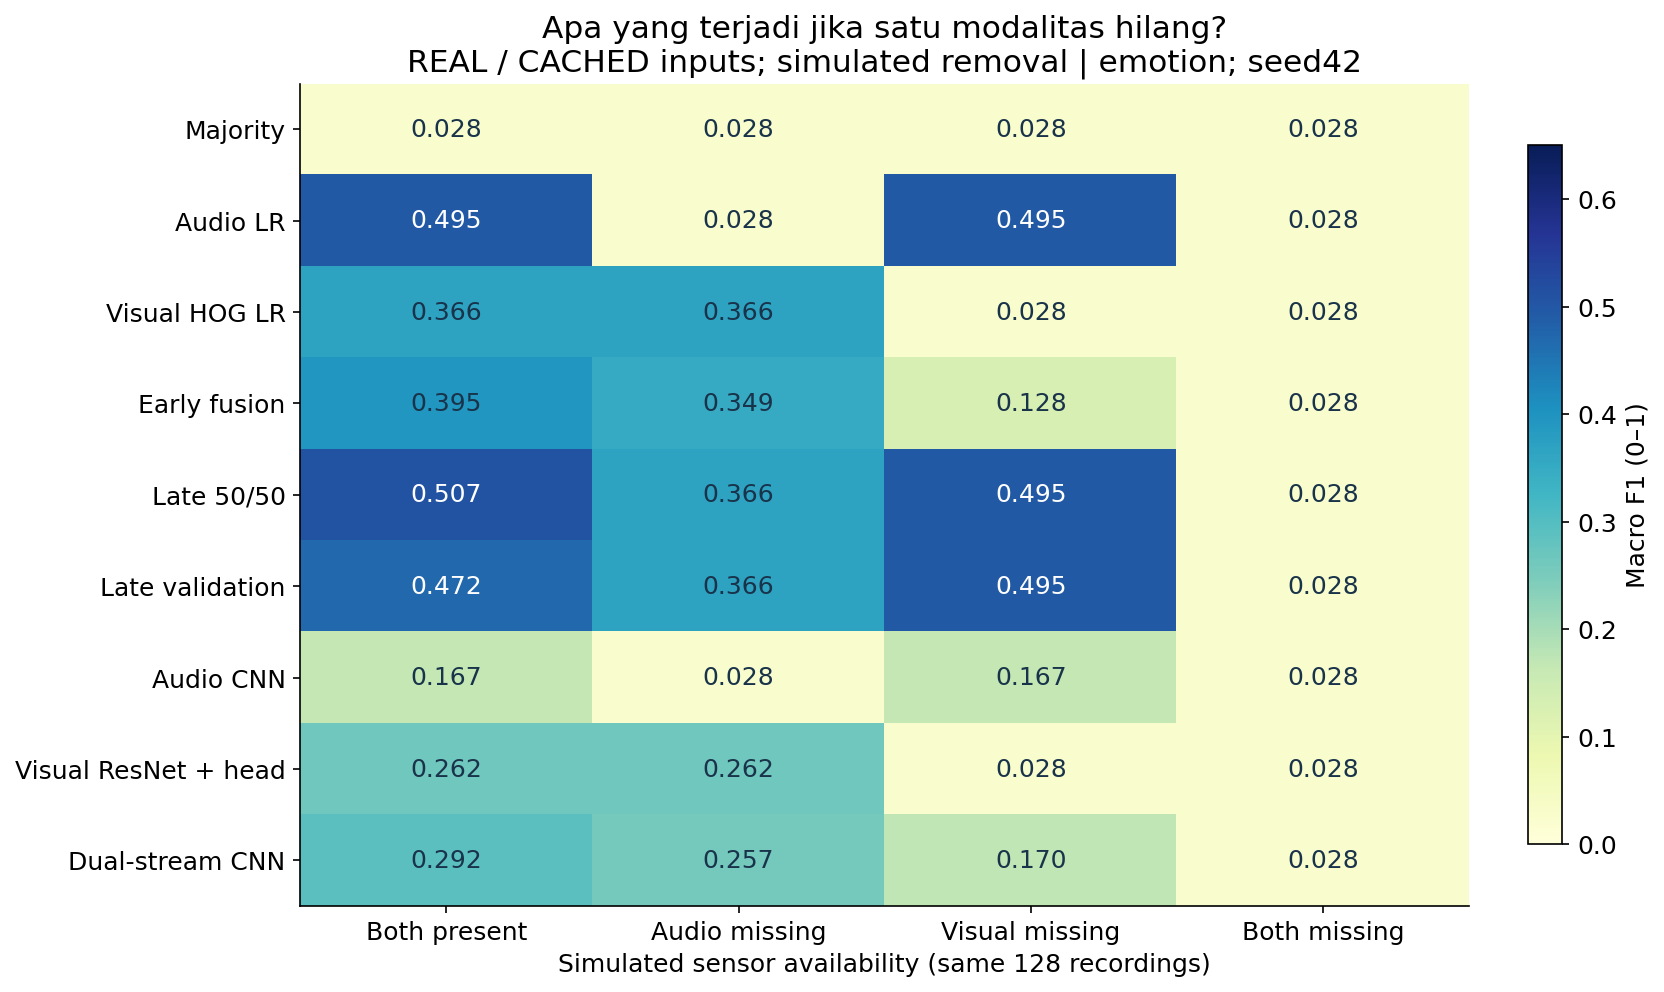

In [10]:
show_extension_figure('missing_modalities')

**Yang terlihat:** Empat skenario availability mengevaluasi recording yang sama; tiap row model memiliki 128 prediksi per skenario.

**Artinya:** Mask dan fallback mendefinisikan apa yang dihitung model ketika sensor hilang; nilai 0 tidak dipakai seolah pengukuran asli.

**Perlu diingat:** Penghapusan sensor simulatif belum menggambarkan semua kegagalan sensor dunia nyata. Keduanya hilang adalah prior fallback, bukan deteksi emotion berbasis data.

---
## B. Dual-Stream CNN — Learned Audio/Visual Feature Fusion

**Pertanyaan:** apakah representasi audio dan visual yang dipelajari memberi generalisasi lebih baik pada aktor baru daripada handcrafted features atau late fusion?

Inspirasi konseptualnya adalah dual-stream feature fusion dari [Xu et al.(2024)](https://doi.org/10.3390/aerospace11020164). Ini **bukan exact reproduction**: paper menggunakan paired ATC radiotelephony/facial fatigue; eksperimen kita memakai RAVDESS emotion, CNN audio kecil, dan frozen ImageNet ResNet-18. Dataset, label, arsitektur, dan protokol berbeda.

Tiga kontrol dilatih: **Audio-CNN-only, Visual-CNN-only, Dual-Stream CNN**. Semua memakai 8 outer fold dan checkpoint selection pada validation actors yang sama dengan metode classical. Seed 42 adalah run utama yang telah ditetapkan; seed 43 adalah sensitivity, bukan kandidat untuk dipilih setelah test.


### Dari file AV ke tensor dan embedding

**Audio:** mono 16 kHz→DC removal→64 Melbands, 25 ms frame/10 ms hop→log power(ref 1/top_db 80). Storage maksimum 6 detik menghasilkan`[N,1,64,598]`. Time-mask menyatakan frame yang benar-benar ada; padding dikecualikan dari train-only mean/std dan masked pooling. Seluruh audio aktual kurang dari 6 detik sehingga tidak ada crop durasi.

**Video:** pilih 8 native frames menurut timestamp 10–90%durasi; YuNet mendeteksi crop wajah 256 RGB, lalu transform resmi ImageNet. Tidak ada whole-frame fallback ketika wajah gagal. ResNet-18 ImageNet pretrained **frozen** menghasilkan`[N,8,512]`; masked mean→512, train-only scaling→learned projection 32. Tidak menggunakan checkpoint hasil training UTA. Semua 1.024 sampledframes berhasil terdeteksi pada subset ini.

**Audio encoder:** tiga Conv2D 3×3(ReLU,pool 2×2), channel 8/16/32→masked average→embedding 32. **Fusion:** concatenation 32+32+2 availability masks→66→hidden 32→8 logits. Mean frame pooling tidak mempertahankan urutan kedipan, sehingga model ini tidak diklaim membaca blink duration/PERCLOS.


In [11]:
representations = load_extension('fusion_extension_representations.json')
example_representation = representations['examples'][0]
print('REAL source; CACHED numeric checkpoint replay:', example_representation['sample_id'])
print('Per-recording input shapes:', example_representation['input_shapes'])
print('Valid time frames / face frames:', example_representation['valid_audio_frames'], example_representation['valid_video_frames'])
print('Audio32 + visual32 + masks2 =', len(example_representation['concatenated66']))
display(pd.DataFrame({'audio_embedding': example_representation['audio_embedding32'], 'visual_embedding': example_representation['visual_embedding32']}).head(12).round(4))


REAL source; CACHED numeric checkpoint replay: 01-01-01-01-01-01-01
Per-recording input shapes: {'audio': [1, 1, 64, 598], 'audio_mask': [1, 598], 'visual': [1, 8, 512], 'frame_mask': [1, 8]}
Valid time frames / face frames: 329 8
Audio32 + visual32 + masks2 = 66


,audio_embedding,visual_embedding
0,0.3223,2.7796
1,3.3643,0.0000
2,3.6274,0.5461
3,0.0000,2.6745
4,0.0000,0.0000
5,0.0000,0.6261
6,1.8455,1.6904
7,0.4063,0.0000
8,2.9450,0.0000
9,3.7342,0.0000


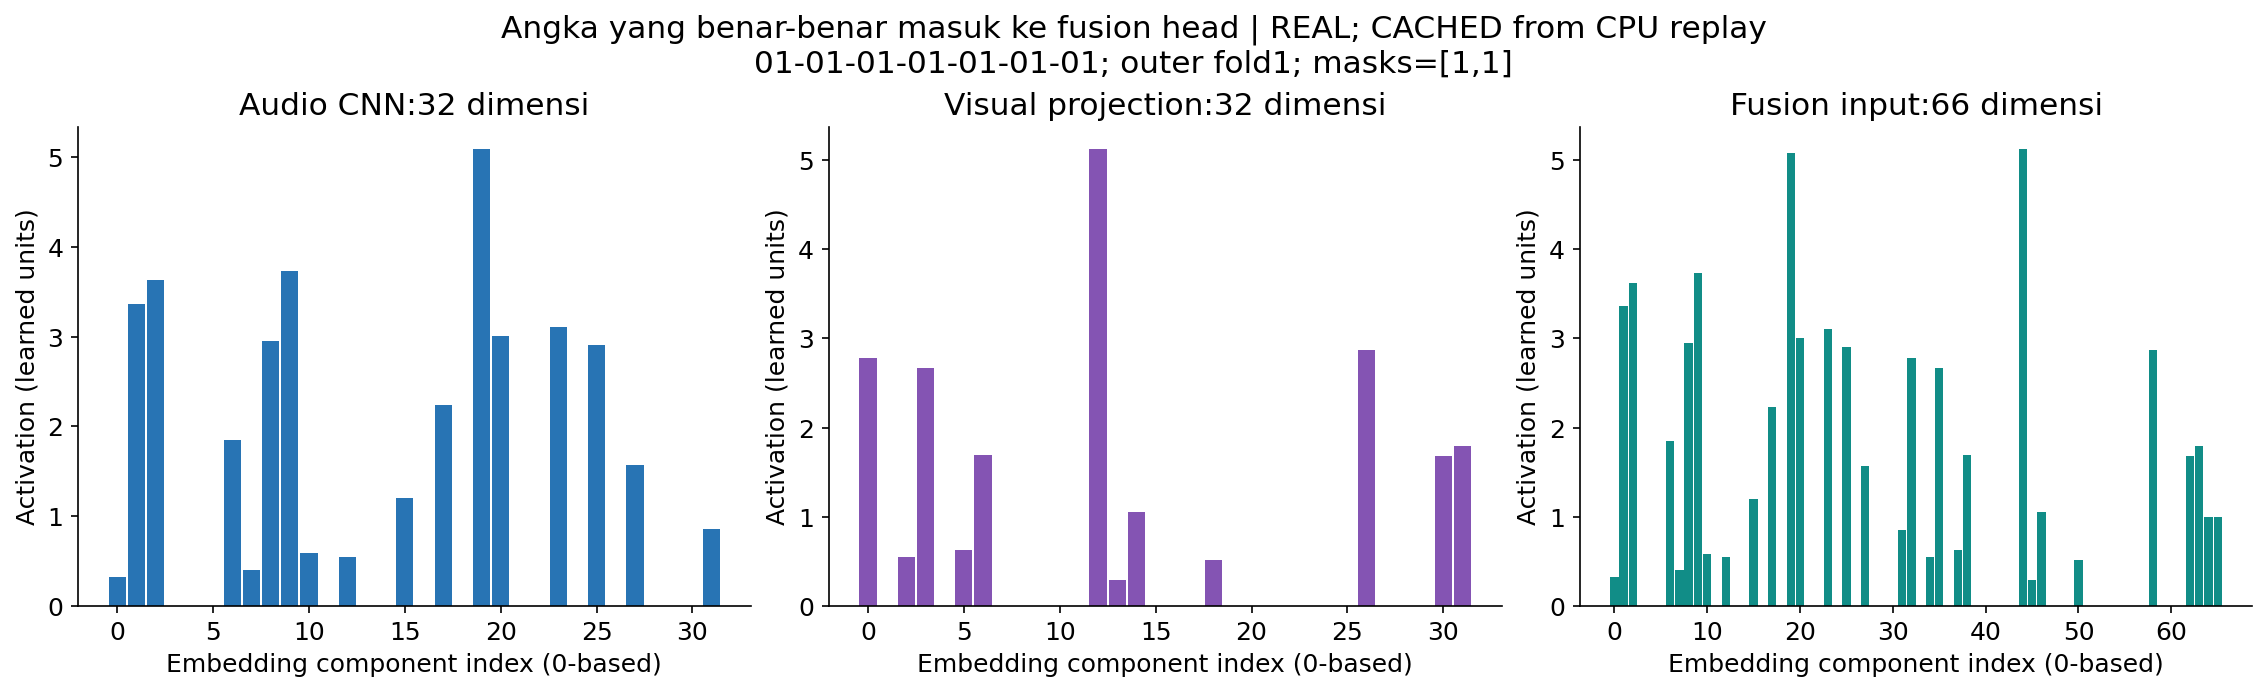

In [12]:
show_extension_figure('actual_embeddings')

**Yang terlihat:** Dua embedding 32 komponen dan vektor gabungan 66 berasal dari recording dan checkpoint yang sama; 2 komponen terakhir adalah mask[1,1].

**Artinya:** Inilah angka yang benar-benar masuk ke fusion head, bukan ilustrasi fitur sintetis.

**Perlu diingat:** Komponen embedding bukan fitur fisiologis yang otomatis dapat dinamai. Grafik adalah CACHED dari CPU float32 replay; evaluasi canonical menggunakan CUDA AMP yang dapat berbeda sedikit secara numerik.

### Training, regularisasi, dan model selection

AdamW(lr 0.001, weight_decay 0.001), batch 16, dropout 0.3, max 60 epoch, min 10 epoch, patience 8, gradientclip 1, CUDA mixed precision. Checkpoint terbaik dipilih dengan validation-actor Macro F1; validation cross-entropy hanya pemecah seri. Outer-test tidak dipakai memilih epoch, seed, atau arsitektur.

Dual-stream mendapat train-only modality dropout:15%audio saja, 15%visual saja, 70%keduanya. AudioCNN dan fusion head dilatih dari awal; ResNet tetap frozen. Hanya 80 recording train/fold menyebabkan risiko overfitting besar walaupun parameter head kecil. Biaya backbone frozen tetap dihitung pada total deployment.


In [13]:
neural_resources = [row for row in extension['resources'] if row['family'] == 'neural']
complexity = []
for model in ['audio_cnn','visual_cnn','dual_stream_cnn']:
    stages = [row for row in neural_resources if row['model'] == model]
    complexity.append({'model': model, **stages[0]['parameters'], 'train_seconds_16_stages': sum(row['training_seconds'] for row in stages), 'peak_allocated_MiB': max(row['peak_gpu_allocated_bytes'] for row in stages)/1024**2})
display(pd.DataFrame(complexity).drop(columns='checkpoint_scope').round(3))


,model,trainable,frozen_shared_ImageNet_encoder,total_deployed,train_seconds_16_stages,peak_allocated_MiB
0,audio_cnn,7208,0,7208,17.082,60.449
1,visual_cnn,16680,11176512,11193192,7.726,8.054
2,dual_stream_cnn,25768,11176512,11202280,20.382,60.665


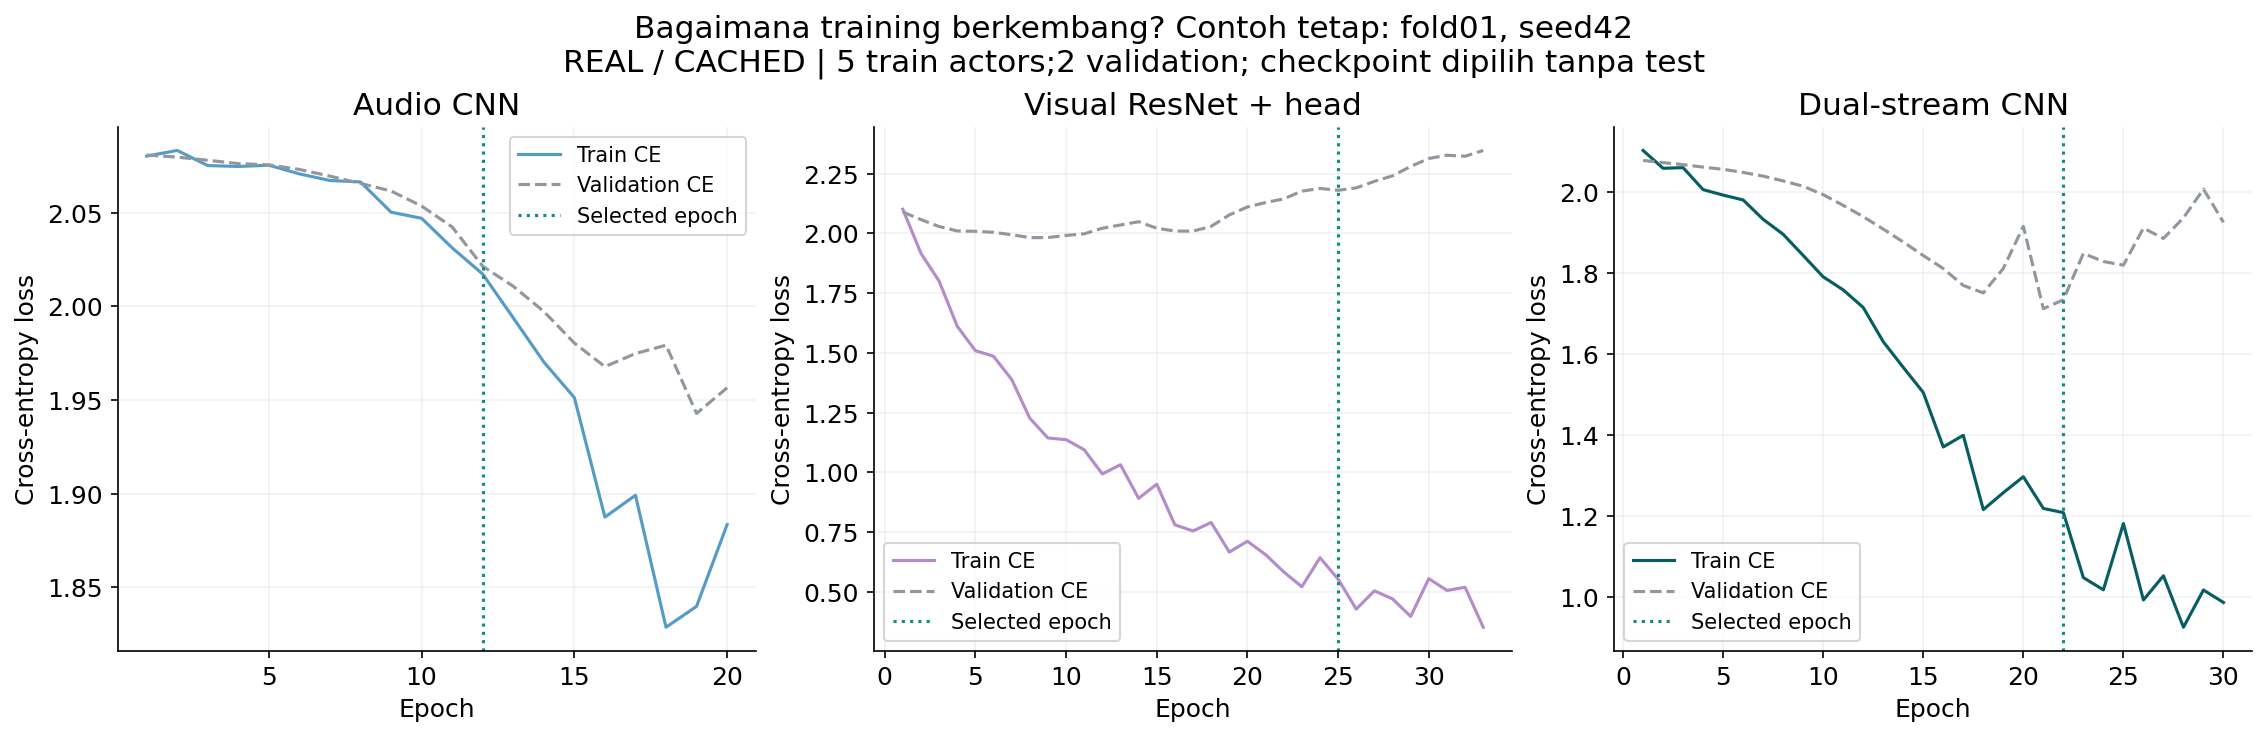

In [14]:
show_extension_figure('learning_curves')

**Yang terlihat:** Pada contoh tetap fold 01, visual train loss turun tetapi validation loss naik; dual-stream juga memperlihatkan gap train–validation.

**Artinya:** Ada pola yang sesuai dengan overfitting. Menambah kapasitas tidak otomatis memperbaiki transfer ke aktor baru.

**Perlu diingat:** Fold 01 dipilih berdasarkan nomor sebelum menilai grafik. Seluruh 48 riwayat tersedia lokal; checkpoint dipilih melalui validation Macro F1, bukan titik loss test.

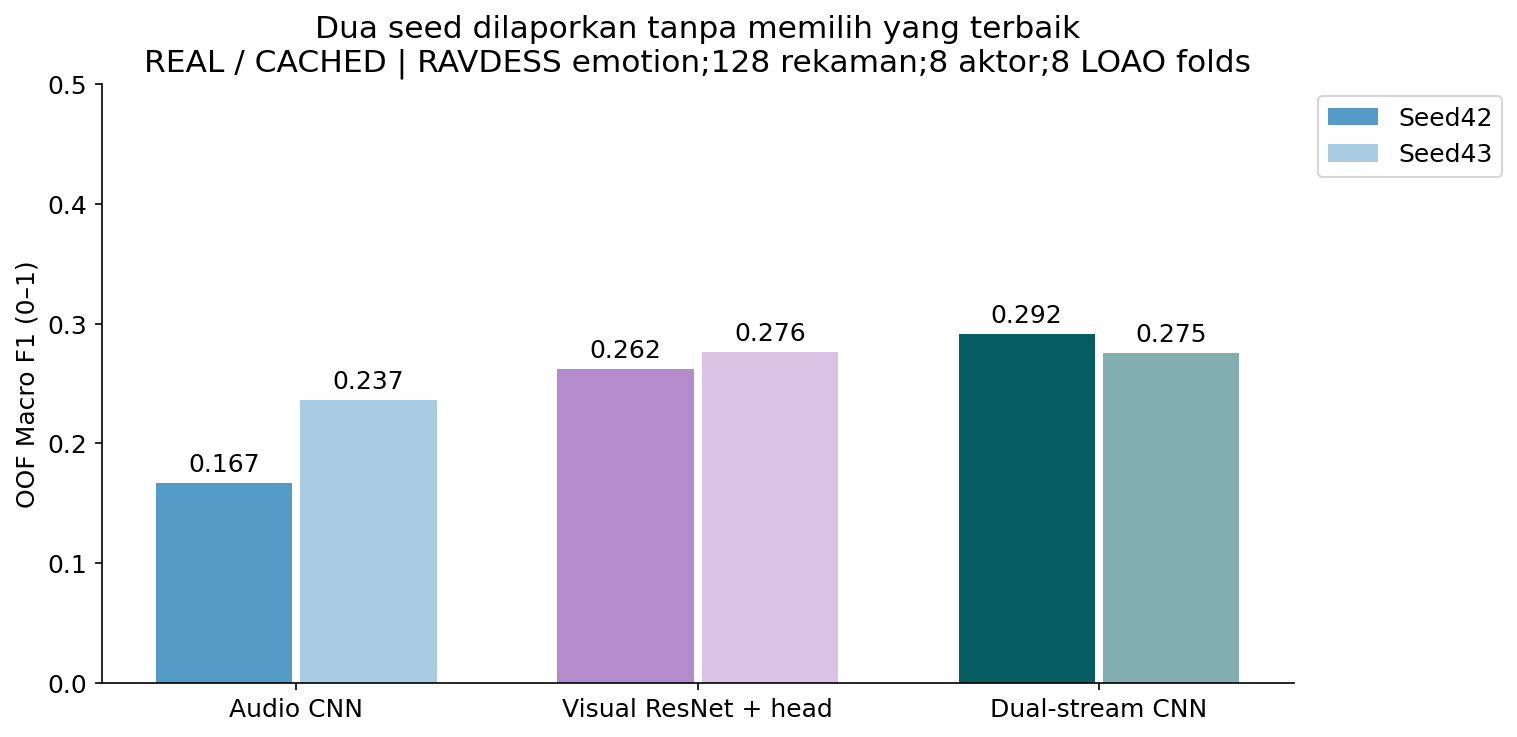

In [15]:
show_extension_figure('seed_sensitivity')

**Yang terlihat:** Dual-stream Macro F1=0.2916(seed 42) dan 0.2753(seed 43); audioCNN=0.1670/0.2367; visualCNN=0.2624/0.2765.

**Artinya:** Hasil training sensitif terhadap seed; seluruh run dilaporkan tanpa memilih pemenang berdasarkan test.

**Perlu diingat:** Dua seed masih terlalu sedikit untuk menggambarkan semua variasi. Dual-stream tidak konsisten lebih baik daripada visualCNN pada kedua seed.

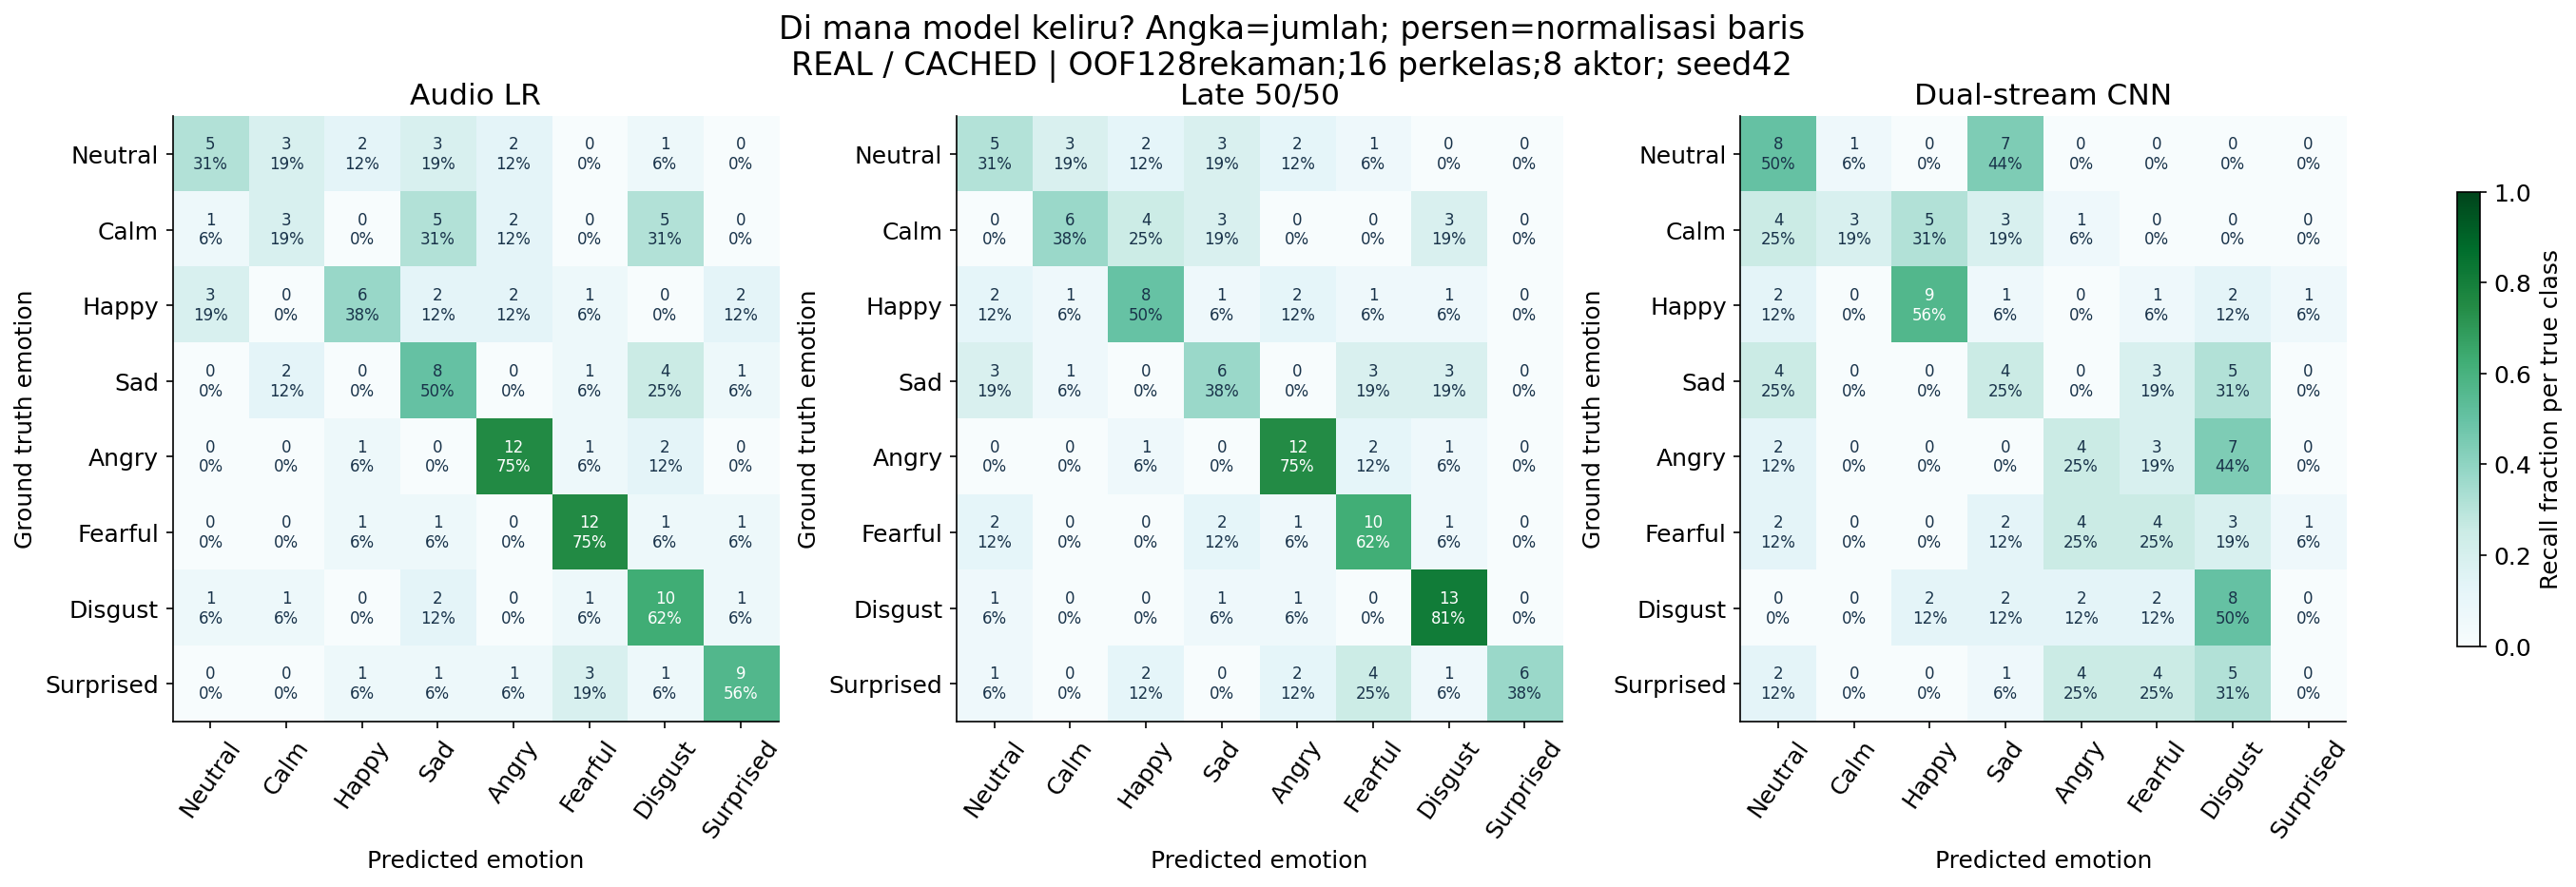

In [16]:
show_extension_figure('confusions')

**Yang terlihat:** Angka absolut dan normalisasi baris memakai 128 OOF recording, 16 perkelas. Dual-stream tidak mengenali Surprised dengan benar pada seed 42.

**Artinya:** Kelemahan perkelas terlihat meskipun satu angka rata-rata menyembunyikannya. Audio/Late lebih baik pada sejumlah kelas.

**Perlu diingat:** Emotion diperagakan oleh aktor. Kegagalan tidak dapat langsung dikaitkan dengan tingkat kantuk atau fisiologi fatigue.

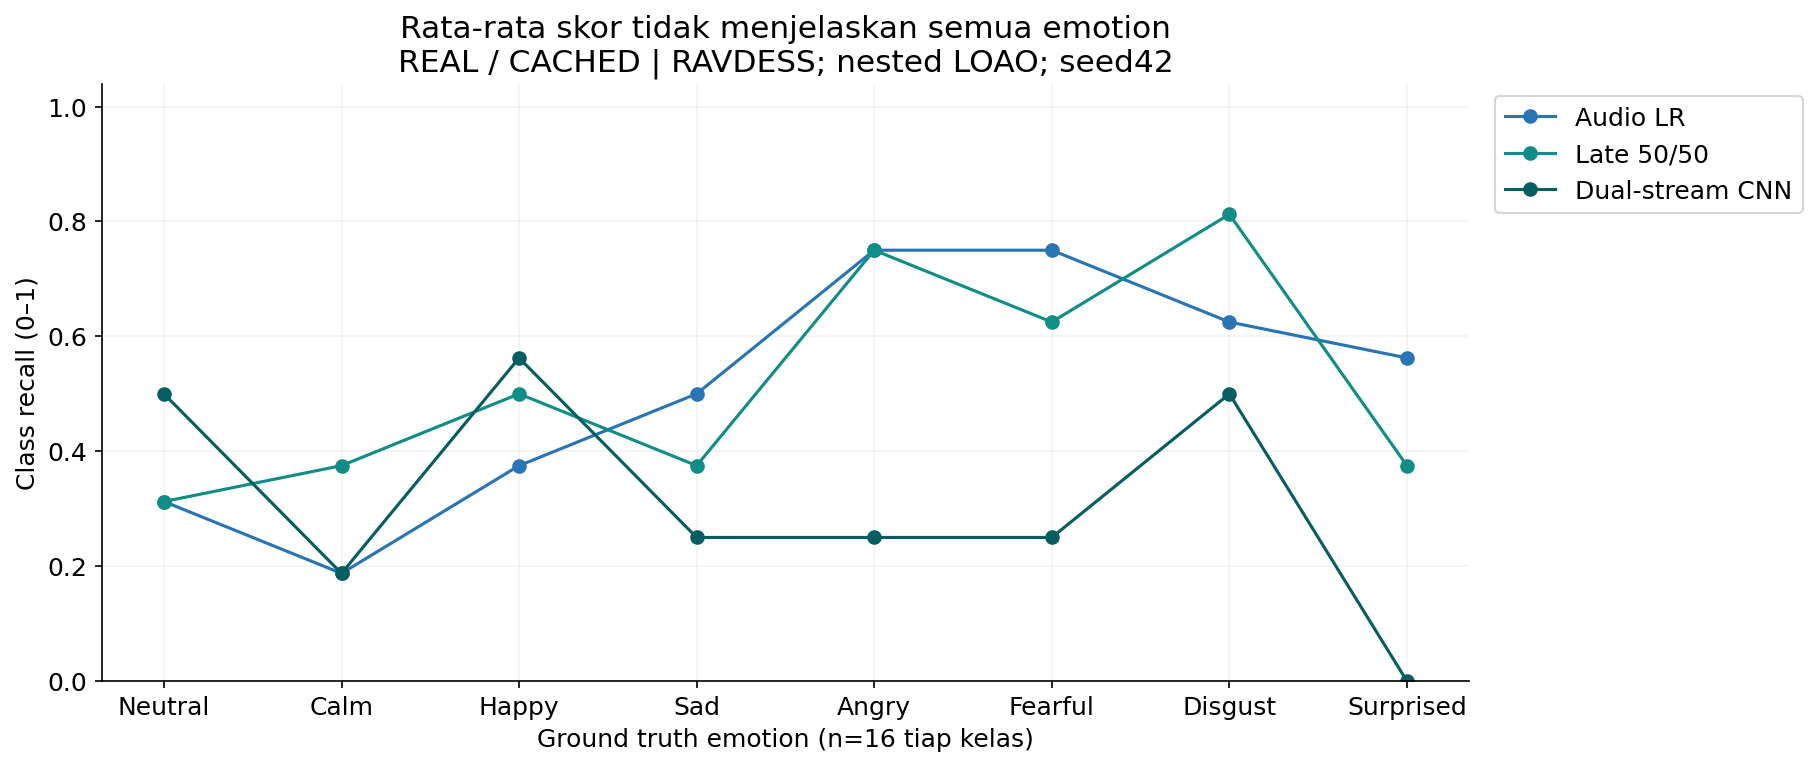

In [17]:
show_extension_figure('class_recall')

**Yang terlihat:** Recall bervariasi antar emotion; misalnya Angry audio LRdanLate 50/50 sama-sama 12/16, sedangkan dual-stream 4/16.

**Artinya:** Fusion dapat membantu kelas tertentu dan merugikan kelas lain; distribusi error perlu diperiksa bersama Macro F1.

**Perlu diingat:** Support 16 perkelas kecil. Accuracy=BalancedAccuracydi sini karena kelas seimbang, bukan karena dua metrik selalu setara.

### Prediksi langkah demi langkah: recording yang sama, termasuk kegagalan

Tabel dipilih deterministik: sample ID terkecil, error dual-stream pertama, dan success pertama jika ada; duplikat digabung. Ground truth tidak dipakai untuk memilih contoh ‘terbaik’. Semua prediksi memakai test recording yang sama untuk setiap model.

Langkahnya: baca paired recording→ekstrak log-Mel dan 8 frame→audioembedding 32/visualembedding 32→concat 66→class logits 8→probabilitas→argmax→bandingkan dengan label emotion. Tabel di bawah menyertakan semua baseline sehingga ketidaksetujuan tetap terlihat.


In [18]:
cases = pd.DataFrame(extension['examples'])
display(cases)
per_class = []
for model in ['audio_logistic','late_equal','dual_stream_cnn']:
    report = extension['metrics'][f'{model}/seed42/complete']['classification_report']
    for label, emotion in extension['labels'].items():
        per_class.append({'model': model, 'emotion': emotion, **{key: report[label][key] for key in ['precision','recall','f1-score','support']}})
display(pd.DataFrame(per_class).round(3))


,sample_id,subject_id,truth,audio_cnn,audio_logistic,dual_stream_cnn,dummy_majority,early_fusion,late_equal,late_weighted,visual_cnn,visual_logistic
0,01-01-01-01-01-01-01,01,1,4,4,2,1,7,4,4,2,7
1,01-01-01-01-01-01-02,02,1,8,5,1,1,8,5,5,1,1


,model,emotion,precision,recall,f1-score,support
0,audio_logistic,Neutral,0.500,0.312,0.385,16.0
1,audio_logistic,Calm,0.333,0.188,0.240,16.0
2,audio_logistic,Happy,0.545,0.375,0.444,16.0
3,audio_logistic,Sad,0.364,0.500,0.421,16.0
4,audio_logistic,Angry,0.632,0.750,0.686,16.0
5,audio_logistic,Fearful,0.632,0.750,0.686,16.0
6,audio_logistic,Disgust,0.417,0.625,0.500,16.0
7,audio_logistic,Surprised,0.643,0.562,0.600,16.0
8,late_equal,Neutral,0.357,0.312,0.333,16.0
9,late_equal,Calm,0.545,0.375,0.444,16.0


In [19]:
# Optional local checkpoint replay: no training and no media display.
# Public-only checkout falls back transparently to the verified saved predictions.
import sys
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
local_run = PROJECT_ROOT / extension['run']
if (local_run / 'classical/fold01/models.joblib').is_file():
    import joblib
    bundle = joblib.load(local_run / 'classical/fold01/models.joblib')
    features = pd.read_parquet(PROJECT_ROOT / extension['config']['historical_features_run'] / 'features/features.parquet')
    source_row = features[features.sample_id.eq(example_representation['sample_id'])]
    probability = bundle['models']['audio_logistic'].predict_proba(source_row[bundle['columns']['audio_logistic']])
    replay_prediction = int(bundle['models']['audio_logistic'].classes_[probability.argmax(1)[0]])
    expected = int(cases.set_index('sample_id').loc[example_representation['sample_id'], 'audio_logistic'])
    assert replay_prediction == expected
    print('FRESH: audio Logistic checkpoint inference matches cached OOF:', replay_prediction)
else:
    print('CACHED: public predictions; local model/cache unavailable; no fresh inference claimed.')


FRESH: audio Logistic checkpoint inference matches cached OOF: 4


### Kesimpulan ilmiah dan reproduksi

**Apakah pipeline multimodal berhasil dilatih? Ya.** Ada 8 classical fold, 48 neural stage(3 model×8 fold×2 seed), checkpoint replay dan 6.144 baris prediksi termasuk 4 availability scenarios pada recording yang sama. Normalisasi seluruh 48 checkpoint diperiksa kembali menggunakan training actor saja.

**Apakah fusion konsisten unggul? Belum.** Late 50/50 sedikit lebih tinggi daripada audio LR pada pooled OOF(+0.0119), tetapi interval selisih mencakup nol dan penurunan besar terjadi pada 2 aktor. Weighted late tidak mengungguli audio. Dual-stream lebih baik daripada audioCNN, tetapi kalah dari audio LR pada 7/8 aktor dan tidak konsisten mengungguli visualCNN. Menambah neural encoder belum memberi bukti peningkatan yang kuat pada subset ini.

Actor-bootstrap 1000 draw(seed 42) mempertahankan semua recording seorang aktor bersama-sama. Interval hanya bersifat deskriptif untuk fixed OOF predictions, tidak memasukkan retraining uncertainty; 8 aktor dan overlapping training folds membatasi inferensi. Tidak ada klaim occupational fatigue accuracy.

**Reproduksi training baru:** dari root proyek jalankan`PYTHONPATH=src .venv/bin/python scripts/run_coordinated_research.py --packages late cnn --no-acquisition`. Tambahkan`--resume <coordinator-run>`untuk memverifikasi dan memakai stage completed tanpa training ulang. Raw media, full feature cache, dan checkpoints tetap lokal. [Laporan lengkap](../../reports/fusion_extension_research.md) · [Instruksi](../../docs/fusion_extension.md) · [Metrik/provenance](../../reports/fusion_extension_results.json).

Langkah ATC berikutnya memerlukan paired audio-video dan fatigue labels yang benar-benar dikumpulkan dari populasi relevan. UTA drowsiness, RAVDESS emotion, dan Predi-COVID proxy tidak boleh dipasangkan atau disamakan sebagai satu ground truth.
